# 10 — Kumo + spline: EDA hingga submission.csv

Resep tetap: **75% Kumo Large + 25% spline dengan fitur laten**.
Kumo memakai bobot pretrained; spline mempelajari hubungan aditif nonlinier dari
training fold. Tiga fold screening memakai seed 8247, lima fold berikutnya seed 31027.
Setiap perbandingan memakai pembagian baris yang sama untuk baseline dan gabungan.

Label serta lima split sudah pernah dipakai untuk eksperimen sebelumnya. Ini adalah
pemeriksaan konsistensi dengan pemilihan model berulang, bukan holdout yang belum
pernah dilihat. Skor public kandidat baru **belum diketahui**. Checkpoint Kumo
`submission_kumo.csv` dengan public 0,56262 tetap disimpan.

Gunakan Python 3.11, requirements-kumo.txt, GPU CUDA dan data mentah kompetisi.
Semua kode fitur, konteks Kumo, fitting spline, prediksi dan ekspor terlihat di sel.


## Persiapan

Fitur dibangun dari data mentah jika cache belum tersedia.

In [1]:
RUN_NAME = "10_kumo_spline"
CANONICAL_FILE = "submission_kumo_v2.csv"
PUBLIC_SCORE = None

from pathlib import Path
import gc, hashlib, itertools, json, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import ks_2samp
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from threadpoolctl import threadpool_limits

# Ubah empat pilihan ini jika ingin membangun dan melatih semuanya ulang.
FORCE_REBUILD_FEATURES = False
FORCE_RETRAIN_MODELS = False
FORCE_RECOMPUTE_VALIDATION = False
RUN_OPTIONAL_SEARCH = False

ROOT = Path(os.environ.get("LOGIKA_PROJECT_DIR", Path.cwd())).resolve()
if not (ROOT / "scripts/analyze.py").exists():
    ROOT = next(p for p in ROOT.parents if (p / "scripts/analyze.py").exists())
RAW = ROOT / "data/raw"
PROCESSED = Path(os.environ.get("LOGIKA_FEATURE_DIR", ROOT / "data/processed"))
OUT = ROOT / "artifacts/notebook_runs" / RUN_NAME
TABLES = OUT / "tables"
for folder in [PROCESSED, OUT, TABLES, OUT / "models"]:
    folder.mkdir(parents=True, exist_ok=True)
KEY, TARGET = "customer_id", "target"
EXCLUDED = {
    "application_id",
    "customer_id",
    "application_datetime",
    "decision_datetime",
    "target",
    "split",
}
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 20)
print("Proyek:", ROOT)
print("Output notebook:", OUT / "submission.csv")
import argparse, importlib.metadata
import torch, sdm
assert torch.cuda.is_available()
print('Torch:', torch.__version__, '; SDM:', sdm.__version__)
import re
from scipy import optimize, special, stats

import joblib


Proyek: /home/taqiyudinmiftah/Logika
Output notebook: /home/taqiyudinmiftah/Logika/artifacts/notebook_runs/10_kumo_spline/submission.csv


/tmp/logika-kumo-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Torch: 2.8.0+cu128 ; SDM: 0.2.1


## 2. Memahami target dan data

`target=1` berarti pinjaman mencapai DPD ≥90 dalam 12 bulan setelah origination. Test tidak memiliki target. Ada satu aplikasi terpilih per customer, sehingga agregasi seluruh tabel riwayat memakai customer_id. Perbedaan rasio target menurut kelompok bersifat deskriptif dan bukan kesimpulan sebab-akibat.

,dataset,baris,kolom,target_positif,rasio_positif
0,train,70000,10,9507.0,0.135814
1,test,30000,9,NaN,NaN


,tipe,missing
application_id,object,0
customer_id,object,0
application_datetime,datetime64[ns],0
decision_datetime,datetime64[ns],0
loan_amount,int64,0
term_months,int64,0
annual_interest_rate,float64,0
proposed_monthly_installment,int64,0
loan_purpose,object,0
target,int64,0


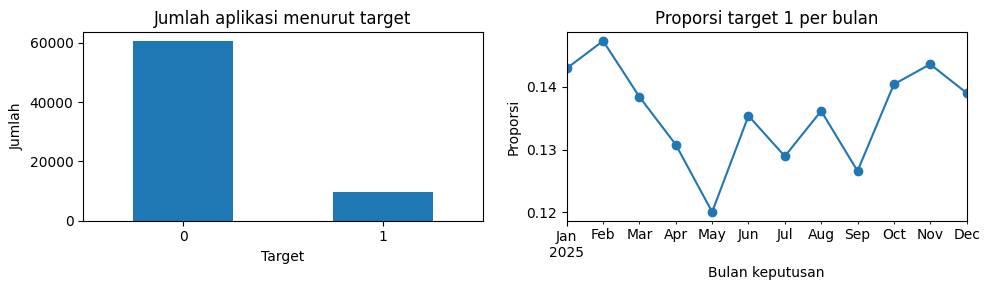

,aplikasi,rasio_target_1
employment_type,,
salaried,33473,0.132405
self_employed,20987,0.137943
variable_income,15540,0.140283


Urutan sample sama dengan test: False


In [2]:
train_raw = pd.read_csv(
    RAW / "train_applications.csv", parse_dates=["application_datetime", "decision_datetime"]
)
test_raw = pd.read_csv(
    RAW / "test_applications.csv", parse_dates=["application_datetime", "decision_datetime"]
)
sample = pd.read_csv(RAW / "sample_submission.csv")
profiles_eda = pd.read_csv(RAW / "customer_profiles.csv")
assert train_raw.application_id.is_unique and test_raw.application_id.is_unique
assert set(train_raw.customer_id).isdisjoint(test_raw.customer_id)
assert set(test_raw.application_id) == set(sample.application_id)
assert train_raw.target.isin([0, 1]).all()
display(
    pd.DataFrame(
        [
            {
                "dataset": "train",
                "baris": len(train_raw),
                "kolom": len(train_raw.columns),
                "target_positif": int(train_raw.target.sum()),
                "rasio_positif": train_raw.target.mean(),
            },
            {
                "dataset": "test",
                "baris": len(test_raw),
                "kolom": len(test_raw.columns),
                "target_positif": np.nan,
                "rasio_positif": np.nan,
            },
        ]
    )
)
display(
    pd.DataFrame({"tipe": train_raw.dtypes.astype(str), "missing": train_raw.isna().sum()})
)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
train_raw.target.value_counts().sort_index().plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Jumlah aplikasi menurut target", xlabel="Target", ylabel="Jumlah")
monthly = train_raw.groupby(train_raw.decision_datetime.dt.to_period("M")).target.agg(
    ["mean", "size"]
)
monthly["mean"].plot(marker="o", ax=axes[1])
axes[1].set(title="Proporsi target 1 per bulan", xlabel="Bulan keputusan", ylabel="Proporsi")
plt.tight_layout()
plt.show()
profile = train_raw[["customer_id", "target"]].merge(
    profiles_eda, on="customer_id", validate="one_to_one"
)
display(profile.groupby("employment_type").target.agg(aplikasi="size", rasio_target_1="mean"))
print("Urutan sample sama dengan test:", sample.application_id.equals(test_raw.application_id))
del profile, profiles_eda

## 3. Metrik KS dan risiko kebocoran

KS adalah maksimum selisih dua distribusi kumulatif skor. Dalam ROC, nilainya sama dengan maksimum |TPR−FPR|. KS mengukur pemisahan; submission tetap berupa probabilitas kontinu. Model validasi tidak boleh dilatih pada baris validasi. Informasi riwayat harus tersedia sebelum decision_datetime, dan opaque ID tidak menjadi fitur.

In [3]:
def ks(y, probability):
    fpr, tpr, _ = roc_curve(y, probability, drop_intermediate=False)
    return float(np.max(np.abs(tpr - fpr)))


def lgb_ks(y, probability):
    return "ks", ks(y, probability), True


def metrics(y, probability):
    return {
        "ks": ks(y, probability),
        "roc_auc": roc_auc_score(y, probability),
        "average_precision": average_precision_score(y, probability),
        "log_loss": log_loss(y, probability),
    }

## 4. Fitur dasar: alat bantu dan pengaturan cache

Sel fitur berikut berisi kode agregasi yang digunakan pada eksperimen asli. Jika parquet tersedia, blok `if NEED_...` dilewati. Aktifkan `FORCE_REBUILD_FEATURES` untuk membaca ulang seluruh riwayat. Kode tetap terlihat dan dapat diedit langsung di notebook.

In [4]:
def safe_ratio(a, b):
    return a / b.where(b > 0)


def read(name, dates=()):
    return pd.read_csv(RAW / f"{name}.csv", parse_dates=list(dates))


def ratio(a, b):
    return a / b.where(b > 0)


NEED_BASE = FORCE_REBUILD_FEATURES or not (PROCESSED / "application_features.parquet").exists()
NEED_BASE = NEED_BASE or not (PROCESSED / "bureau_latest.parquet").exists()
print("Bangun fitur dasar:", NEED_BASE)

Bangun fitur dasar: False


### Persiapan audit

Setiap aplikasi memiliki satu customer. Audit mencatat duplikasi, relasi tabel, missing value, dan ketersediaan riwayat.

In [5]:
if NEED_BASE:
    for folder in [PROCESSED, TABLES, OUT / "figures"]:
        folder.mkdir(parents=True, exist_ok=True)
    train = read("train_applications", ["application_datetime", "decision_datetime"])
    test = read("test_applications", ["application_datetime", "decision_datetime"])
    train["split"] = "train"
    test["split"] = "test"
    base = pd.concat([train, test], ignore_index=True)
    assert base.application_id.is_unique and base.customer_id.is_unique
    cutoff = base[[KEY, "decision_datetime"]].rename(columns={"decision_datetime": "cutoff"})
    inventory, missing, audits, coverage = [], [], {}, []

    def inspect(df, name, primary):
        inventory.append(
            {
                "table": name,
                "rows": len(df),
                "columns": len(df.columns),
                "customers": df[KEY].nunique() if KEY in df else np.nan,
                "size_mb": (RAW / f"{name}.csv").stat().st_size / 1e6,
            }
        )
        for col in df:
            missing.append(
                {
                    "table": name,
                    "column": col,
                    "dtype": str(df[col].dtype),
                    "missing": int(df[col].isna().sum()),
                    "missing_pct": 100 * df[col].isna().mean(),
                    "unique_values": df[col].nunique(),
                }
            )
        audits[name] = {
            "duplicate_rows": int(df.duplicated().sum()),
            "duplicate_primary_keys": int(df.duplicated(primary).sum()),
        }
        if KEY in df:
            ids = set(df[KEY])
            audits[name]["orphan_customers"] = len(ids - set(base[KEY]))
            for part in ["train", "test"]:
                subset = base[base.split.eq(part)]
                coverage.append(
                    {
                        "table": name,
                        "split": part,
                        "covered_customers": int(subset[KEY].isin(ids).sum()),
                        "coverage_pct": 100 * subset[KEY].isin(ids).mean(),
                    }
                )
        print(f"Audited {name}: {len(df):,} rows", flush=True)

    def at_cutoff(df, name, cols):
        df = df.merge(cutoff, on=KEY, how="left", validate="many_to_one")
        assert df.cutoff.notna().all()
        for col in cols:
            audits[name][f"{col}_at_or_after_cutoff"] = int(df[col].ge(df.cutoff).sum())
        return df

    def attach(features):
        global base
        assert features.index.is_unique
        base = base.merge(
            features, left_on=KEY, right_index=True, how="left", validate="one_to_one"
        )
        assert len(base) == len(train) + len(test)

### Profil dan rasio kemampuan bayar

Gabungkan profil satu-ke-satu; rasio cicilan/pendapatan lebih mudah dipelajari model daripada dua jumlah rupiah terpisah.

In [6]:
if NEED_BASE:
    inspect(train.drop(columns="split"), "train_applications", "application_id")
    inspect(test.drop(columns="split"), "test_applications", "application_id")
    submission = read("sample_submission")
    inspect(submission, "sample_submission", "application_id")
    audits["submission"] = {
        "same_id_set_as_test": set(submission.application_id) == set(test.application_id),
        "same_row_order_as_test": submission.application_id.equals(test.application_id),
        "target_column": "default_probability",
    }
    profiles = read("customer_profiles")
    inspect(profiles, "customer_profiles", KEY)
    base = base.merge(profiles, on=KEY, how="left", validate="one_to_one")
    assert base.age.notna().all()
    base["installment_income_ratio"] = safe_ratio(
        base.proposed_monthly_installment, base.declared_monthly_income
    )
    base["loan_income_ratio"] = safe_ratio(base.loan_amount, base.declared_monthly_income)
    base["income_per_dependent"] = base.declared_monthly_income / (1 + base.dependents)
    base["decision_delay_hours"] = (
        base.decision_datetime - base.application_datetime
    ).dt.total_seconds() / 3600
    rate = base.annual_interest_rate / 12
    theoretical = (
        base.loan_amount
        * rate
        * (1 + rate) ** base.term_months
        / ((1 + rate) ** base.term_months - 1)
    )
    audits["applications"] = {
        "train_test_customer_overlap": len(set(train[KEY]) & set(test[KEY])),
        "train_test_application_overlap": len(
            set(train.application_id) & set(test.application_id)
        ),
        "decision_before_application": int(
            (base.decision_datetime < base.application_datetime).sum()
        ),
        "nonpositive_income": int(base.declared_monthly_income.le(0).sum()),
        "installment_formula_max_rounding_difference_idr": float(
            abs(base.proposed_monthly_installment - theoretical.round()).max()
        ),
        "term_months_values": sorted(base.term_months.unique().tolist()),
    }
    del profiles

### Riwayat aplikasi

Ambil keputusan sebelum cutoff. Hitung persetujuan, penolakan, dan jarak waktu aplikasi terakhir.

In [7]:
if NEED_BASE:
    name = "previous_applications"
    prev = read(name, ["application_datetime", "decision_datetime"])
    inspect(prev, name, "application_id")
    historical_ids = set(prev.application_id)
    approved_loans = set(prev.loan_id.dropna())
    loan_customers = prev.loc[prev.loan_id.notna(), ["loan_id", KEY]].set_index("loan_id")[KEY]
    audits[name]["overlap_with_selected_application_ids"] = len(
        historical_ids & set(base.application_id)
    )
    prev = at_cutoff(prev, name, ["application_datetime", "decision_datetime"])
    prev = prev[prev.decision_datetime.lt(prev.cutoff)].copy()
    for status in ["approved", "rejected", "cancelled"]:
        prev[f"is_{status}"] = prev.decision.eq(status).astype(int)
    prev["recency_days"] = (prev.cutoff - prev.decision_datetime).dt.total_seconds() / 86400
    features = prev.groupby(KEY).agg(
        previous_count=("application_id", "size"),
        previous_approved_count=("is_approved", "sum"),
        previous_rejection_rate=("is_rejected", "mean"),
        previous_cancel_rate=("is_cancelled", "mean"),
        previous_requested_mean=("requested_amount", "mean"),
        previous_approved_amount_mean=("approved_amount", "mean"),
        previous_installment_mean=("scheduled_monthly_installment", "mean"),
        previous_last_recency_days=("recency_days", "min"),
    )
    for days in [90, 180]:
        features[f"previous_count_{days}d"] = (
            prev[prev.recency_days.le(days)]
            .groupby(KEY)
            .size()
            .reindex(features.index, fill_value=0)
        )
    attach(features)
    base["has_previous"] = base.previous_count.notna().astype(int)
    del prev, features
    gc.collect()

### Riwayat pembayaran

DPD adalah days past due. Snapshot pembayaran harus diketahui sebelum keputusan, termasuk waktu pembayaran terakhir.

In [8]:
if NEED_BASE:
    name = "repayment_history"
    repay = read(name, ["due_date", "last_payment_datetime"])
    inspect(repay, name, "installment_id")
    audits[name]["loans_not_in_approved_history"] = len(set(repay.loan_id) - approved_loans)
    audits[name]["loan_customer_mismatches"] = int(
        repay.loan_id.map(loan_customers).ne(repay[KEY]).sum()
    )
    audits[name]["amount_paid_above_due"] = int(repay.amount_paid.gt(repay.amount_due).sum())
    audits[name]["max_dpd_below_current_dpd"] = int(
        repay.max_days_past_due.lt(repay.days_past_due).sum()
    )
    repay = at_cutoff(repay, name, ["due_date", "last_payment_datetime"])
    repay = repay[repay.due_date.lt(repay.cutoff)].copy()
    # Snapshot amounts/DPD are already measured before the selected decision.
    # Any future observed payment would invalidate this snapshot; do not silently use it.
    assert (
        repay.last_payment_datetime.dropna()
        .lt(repay.loc[repay.last_payment_datetime.notna(), "cutoff"])
        .all()
    )
    repay["unpaid_amount"] = (repay.amount_due - repay.amount_paid).clip(lower=0)
    for threshold in [1, 30, 90]:
        repay[f"ever_dpd_{threshold}"] = repay.max_days_past_due.ge(threshold).astype(int)
    repay["recency_days"] = (repay.cutoff - repay.due_date).dt.total_seconds() / 86400
    features = repay.groupby(KEY).agg(
        repayment_installment_count=("installment_id", "size"),
        repayment_loan_count=("loan_id", "nunique"),
        repayment_amount_due=("amount_due", "sum"),
        repayment_amount_paid=("amount_paid", "sum"),
        repayment_unpaid_amount=("unpaid_amount", "sum"),
        repayment_current_dpd_max=("days_past_due", "max"),
        repayment_historical_dpd_max=("max_days_past_due", "max"),
        repayment_historical_dpd_mean=("max_days_past_due", "mean"),
        repayment_late_share=("ever_dpd_1", "mean"),
        repayment_dpd30_share=("ever_dpd_30", "mean"),
        repayment_dpd90_share=("ever_dpd_90", "mean"),
    )
    features["repayment_paid_ratio"] = safe_ratio(
        features.repayment_amount_paid, features.repayment_amount_due
    )
    recent = (
        repay[repay.recency_days.le(180)]
        .groupby(KEY)
        .agg(
            repayment_dpd_mean_180d=("max_days_past_due", "mean"),
            repayment_unpaid_180d=("unpaid_amount", "sum"),
        )
    )
    attach(features.join(recent))
    base["has_repayments"] = base.repayment_installment_count.notna().astype(int)
    del repay, features, recent
    gc.collect()

### Perilaku rekening

Hanya bulan kalender yang sudah selesai yang digunakan; rangkum pemasukan, pengeluaran, saldo, dan hari saldo rendah.

In [9]:
if NEED_BASE:
    name = "account_behavior"
    account = read(name, ["month"])
    inspect(account, name, [KEY, "month"])
    account = at_cutoff(account, name, ["month"])
    completed = account.month + pd.offsets.MonthBegin(1)
    audits[name]["incomplete_month_at_cutoff"] = int(completed.gt(account.cutoff).sum())
    audits[name]["balance_identity_mismatches"] = int(
        (account.opening_balance + account.inflows - account.outflows)
        .ne(account.closing_balance)
        .sum()
    )
    audits[name]["negative_amount_cells"] = int(
        account.select_dtypes(include="number").lt(0).sum().sum()
    )
    account = account[completed.le(account.cutoff)].copy()
    account["net_inflow"] = account.inflows - account.outflows
    account["recency_days"] = (account.cutoff - account.month).dt.total_seconds() / 86400
    features = account.groupby(KEY).agg(
        account_month_count=("month", "size"),
        account_income_mean=("income_like_credits", "mean"),
        account_income_std=("income_like_credits", "std"),
        account_inflow_mean=("inflows", "mean"),
        account_outflow_mean=("outflows", "mean"),
        account_net_inflow_mean=("net_inflow", "mean"),
        account_average_balance_mean=("average_balance", "mean"),
        account_minimum_balance_min=("minimum_balance", "min"),
        account_low_balance_days_mean=("low_balance_days", "mean"),
        account_last_recency_days=("recency_days", "min"),
    )
    features["account_income_cv"] = safe_ratio(
        features.account_income_std, features.account_income_mean
    )
    last = account.sort_values("month").groupby(KEY).tail(1).set_index(KEY)
    for col in [
        "closing_balance",
        "income_like_credits",
        "average_balance",
        "low_balance_days",
    ]:
        features[f"account_last_{col}"] = last[col]
    # Three complete months immediately preceding the decision month.
    start = account.cutoff.dt.to_period("M").dt.to_timestamp() - pd.DateOffset(months=3)
    recent = (
        account[account.month.ge(start)]
        .groupby(KEY)
        .agg(
            account_income_mean_3m=("income_like_credits", "mean"),
            account_outflow_mean_3m=("outflows", "mean"),
            account_balance_mean_3m=("average_balance", "mean"),
            account_low_balance_days_mean_3m=("low_balance_days", "mean"),
        )
    )
    attach(features.join(recent))
    base["has_account"] = base.account_month_count.notna().astype(int)
    base["observed_declared_income_ratio"] = safe_ratio(
        base.account_income_mean, base.declared_monthly_income
    )
    base["installment_observed_income_ratio"] = safe_ratio(
        base.proposed_monthly_installment, base.account_income_mean
    )
    base["balance_installment_ratio"] = safe_ratio(
        base.account_last_closing_balance, base.proposed_monthly_installment
    )
    del account, features, last, recent
    gc.collect()

### Biro kredit

Laporan harus sudah dibuat dan tersedia sebelum cutoff. Gunakan laporan terakhir per provider; saldo provider tidak dijumlahkan karena cakupan dapat tumpang tindih.

In [10]:
if NEED_BASE:
    name = "bureau_observations"
    bureau = read(name, ["report_datetime", "available_datetime"])
    inspect(bureau, name, "bureau_observation_id")
    audits[name]["unknown_application_ids"] = len(
        set(bureau.application_id) - (historical_ids | set(base.application_id))
    )
    audits[name]["availability_before_report"] = int(
        bureau.available_datetime.lt(bureau.report_datetime).sum()
    )
    audits[name]["score_out_of_range"] = int(
        (bureau.score.notna() & ~bureau.score.between(300, 850)).sum()
    )
    expected_util = safe_ratio(
        bureau.revolving_outstanding_balance, bureau.revolving_credit_limit
    )
    audits[name]["utilization_max_absolute_difference"] = float(
        (bureau.utilization - expected_util).abs().max()
    )
    bureau = at_cutoff(bureau, name, ["report_datetime", "available_datetime"])
    bureau = bureau[
        bureau.report_datetime.lt(bureau.cutoff) & bureau.available_datetime.lt(bureau.cutoff)
    ].copy()
    latest = (
        bureau.sort_values(["report_datetime", "available_datetime", "bureau_observation_id"])
        .groupby([KEY, "bureau_provider"])
        .tail(1)
        .copy()
    )
    latest["report_age_days"] = (
        latest.cutoff - latest.report_datetime
    ).dt.total_seconds() / 86400
    latest["delivery_lag_days"] = (
        latest.available_datetime - latest.report_datetime
    ).dt.total_seconds() / 86400
    features = latest.groupby(KEY).agg(
        bureau_provider_count=("bureau_provider", "size"),
        bureau_scored_count=("score", "count"),
        bureau_score_mean=("score", "mean"),
        bureau_score_min=("score", "min"),
        bureau_score_max=("score", "max"),
        bureau_debt_max=("outstanding_balance", "max"),
        bureau_debt_mean=("outstanding_balance", "mean"),
        bureau_active_accounts_max=("active_accounts", "max"),
        bureau_utilization_max=("utilization", "max"),
        bureau_inquiries_max=("inquiries_last_6m", "max"),
        bureau_delinquent_accounts_max=("delinquent_accounts_last_12m", "max"),
        bureau_report_age_mean=("report_age_days", "mean"),
        bureau_delivery_lag_mean=("delivery_lag_days", "mean"),
    )
    features["bureau_score_spread"] = features.bureau_score_max - features.bureau_score_min
    # Provider balances can overlap; summing would imply unsupported unique debt.
    for col in ["score", "utilization", "outstanding_balance", "report_age_days"]:
        pivot = latest.pivot(index=KEY, columns="bureau_provider", values=col)
        pivot.columns = [f"bureau_{provider}_{col}" for provider in pivot.columns]
        features = features.join(pivot)
    attach(features)
    base["bureau_debt_income_ratio"] = safe_ratio(
        base.bureau_debt_max, base.declared_monthly_income
    )
    latest.drop(columns="cutoff").to_parquet(PROCESSED / "bureau_latest.parquet", index=False)
    del bureau, latest, features, pivot
    gc.collect()

### Transaksi e-commerce

`order_total` berulang di setiap barang. Deduplicasi pesanan sebelum menjumlahkan belanja; transaksi cancelled bukan pengeluaran.

In [11]:
if NEED_BASE:
    name = "ecommerce_transactions"
    ecom = read(name, ["transaction_datetime"])
    inspect(ecom, name, "order_item_id")
    # A transaction row is an ITEM, not an order. Verify before deduplicating.
    order_fields = [
        KEY,
        "transaction_datetime",
        "order_total",
        "payment_method",
        "order_status",
    ]
    inconsistent = (
        ecom.groupby("order_id")[order_fields].nunique(dropna=False).gt(1).any(axis=1)
    )
    audits[name]["inconsistent_order_fields"] = int(inconsistent.sum())
    assert not inconsistent.any()
    order_sums = ecom.groupby("order_id").item_total.sum()
    orders = ecom.drop_duplicates("order_id")[["order_id"] + order_fields].copy()
    audits[name]["order_total_mismatches"] = int(
        orders.order_id.map(order_sums).ne(orders.order_total).sum()
    )
    audits[name]["orders"] = len(orders)
    audits[name]["items"] = len(ecom)
    audits[name]["naive_completed_spend_idr"] = int(
        ecom.loc[ecom.order_status.eq("completed"), "order_total"].sum()
    )
    audits[name]["correct_completed_spend_idr"] = int(
        orders.loc[orders.order_status.eq("completed"), "order_total"].sum()
    )
    category_spend = (
        ecom[ecom.order_status.eq("completed")]
        .groupby([KEY, "product_category"])
        .item_total.sum()
        .unstack(fill_value=0)
    )
    # category_spend is safe only when all raw events precede the cutoff (audited below).
    del ecom, order_sums, inconsistent
    gc.collect()
    orders = at_cutoff(orders, name, ["transaction_datetime"])
    assert audits[name]["transaction_datetime_at_or_after_cutoff"] == 0
    orders = orders[orders.transaction_datetime.lt(orders.cutoff)].copy()
    orders["cancelled"] = orders.order_status.eq("cancelled").astype(int)
    features = orders.groupby(KEY).agg(
        ecom_order_count=("order_id", "size"), ecom_cancel_rate=("cancelled", "mean")
    )
    completed = orders[orders.order_status.eq("completed")].copy()
    completed["recency_days"] = (
        completed.cutoff - completed.transaction_datetime
    ).dt.total_seconds() / 86400
    features = features.join(
        completed.groupby(KEY).agg(
            ecom_completed_count=("order_id", "size"),
            ecom_spend_sum=("order_total", "sum"),
            ecom_order_value_mean=("order_total", "mean"),
            ecom_order_value_std=("order_total", "std"),
            ecom_last_purchase_recency_days=("recency_days", "min"),
        )
    )
    for days in [90, 180]:
        recent = (
            completed[completed.recency_days.le(days)]
            .groupby(KEY)
            .agg(
                **{
                    f"ecom_completed_count_{days}d": ("order_id", "size"),
                    f"ecom_spend_{days}d": ("order_total", "sum"),
                }
            )
        )
        features = features.join(recent.reindex(features.index, fill_value=0))
    payment = pd.crosstab(
        completed[KEY], completed.payment_method, normalize="index"
    ).add_prefix("ecom_payment_share_")
    features = features.join(payment)
    category_share = category_spend.div(category_spend.sum(axis=1), axis=0).add_prefix(
        "ecom_category_share_"
    )
    attach(features.join(category_share))
    base["ecom_spend90_income_ratio"] = safe_ratio(
        base.ecom_spend_90d / 3, base.declared_monthly_income
    )
    del orders, completed, features, category_spend, category_share, payment, recent
    gc.collect()

### Simpan fitur dasar

Nilai tak terhingga menjadi NaN. Nilai kosong struktural tetap tersedia sebagai sinyal untuk model pohon.

In [12]:
if NEED_BASE:
    base.replace([np.inf, -np.inf], np.nan, inplace=True)
    base.to_parquet(PROCESSED / "application_features.parquet", index=False)
    pd.DataFrame(inventory).to_csv(TABLES / "table_inventory.csv", index=False)
    pd.DataFrame(missing).to_csv(TABLES / "column_quality.csv", index=False)
    pd.DataFrame(coverage).to_csv(TABLES / "history_coverage.csv", index=False)
    (OUT / "quality_audit.json").write_text(json.dumps(audits, indent=2, ensure_ascii=False))
    print(f"Saved {len(base):,} application rows, {len(base.columns)} columns.", flush=True)
    features_base = base.copy()

In [13]:
features_base = pd.read_parquet(PROCESSED / "application_features.parquet")
print("Fitur dasar:", features_base.shape)

Fitur dasar: (100000, 122)


## 5. Fitur extended: perilaku terbaru dan beban utang

Jendela 30/60/90/180/365 hari membedakan pola terbaru dari seluruh sejarah. Perkiraan sisa pokok menggunakan amortisasi kontraktual dan jumlah cicilan yang diamati; nilainya bukan saldo aktual.

In [14]:
NEED_EXTENDED = (
    FORCE_REBUILD_FEATURES
    or not (PROCESSED / "application_features_extended.parquet").exists()
)

### Persiapan agregasi extended

Semua blok fitur dipertahankan pada indeks customer yang sama.

In [15]:
if NEED_EXTENDED:
    base = pd.read_parquet(PROCESSED / "application_features.parquet").set_index("customer_id")
    cutoff = base[["decision_datetime"]].rename(columns={"decision_datetime": "cutoff"})
    parts = []
    audit = {}

    def attach(f):
        assert f.index.is_unique
        parts.append(f.reindex(base.index))
        print(
            f"Added {len(f.columns)} columns; total added {sum(len(p.columns) for p in parts)}",
            flush=True,
        )

    def history(name, dates):
        df = pd.read_csv(RAW / f"{name}.csv", parse_dates=dates)
        df = df.merge(
            cutoff, left_on="customer_id", right_index=True, how="left", validate="many_to_one"
        )
        assert df.cutoff.notna().all()
        for col in dates:
            audit[f"{name}_{col}_at_or_after_cutoff"] = int(df[col].ge(df.cutoff).sum())
        return df

    def stats(df, cols, prefix, functions=("mean", "std", "min", "max")):
        f = df.groupby("customer_id")[cols].agg(list(functions))
        f.columns = [f"{prefix}_{col}_{fn}" for col, fn in f.columns]
        return f

    # Installment-level patterns and loan-level outcomes observed before cutoff.

### Keterlambatan dan hasil per pinjaman

Rangkum DPD, pembayaran parsial, keterlambatan terbaru, serta hasil per pinjaman.

In [16]:
if NEED_EXTENDED:
    rep = history("repayment_history", ["due_date", "last_payment_datetime"])
    assert rep.last_payment_datetime.isna().sum() + rep.last_payment_datetime.lt(
        rep.cutoff
    ).sum() == len(rep)
    rep = rep[rep.due_date.lt(rep.cutoff)].copy()
    rep["age_days"] = (rep.cutoff - rep.due_date).dt.total_seconds() / 86400
    rep["payment_fraction"] = ratio(rep.amount_paid, rep.amount_due)
    rep["unpaid"] = (rep.amount_due - rep.amount_paid).clip(lower=0)
    rep["unpaid_fraction"] = ratio(rep.unpaid, rep.amount_due)
    rep["partial"] = rep.payment_fraction.between(1e-9, 0.999999).astype(int)
    rep["unpaid_flag"] = rep.amount_paid.eq(0).astype(int)
    rep["late"] = rep.max_days_past_due.gt(0).astype(int)
    rep["dpd30"] = rep.max_days_past_due.ge(30).astype(int)
    rep["dpd60"] = rep.max_days_past_due.ge(60).astype(int)
    rep["dpd90"] = rep.max_days_past_due.ge(90).astype(int)
    rep["payment_delay_days"] = (
        rep.last_payment_datetime - rep.due_date
    ).dt.total_seconds() / 86400
    rep["weighted_dpd"] = rep.max_days_past_due * rep.amount_due
    feature = stats(
        rep,
        [
            "days_past_due",
            "max_days_past_due",
            "payment_fraction",
            "unpaid_fraction",
            "payment_delay_days",
        ],
        "v2_repay",
    )
    for days in [90, 180, 365]:
        subset = rep[rep.age_days.le(days)]
        f = subset.groupby("customer_id").agg(
            n=("loan_id", "size"),
            loans=("loan_id", "nunique"),
            due=("amount_due", "sum"),
            paid=("amount_paid", "sum"),
            unpaid=("unpaid", "sum"),
            dpd_mean=("max_days_past_due", "mean"),
            dpd_max=("max_days_past_due", "max"),
            current_dpd_max=("days_past_due", "max"),
            late_share=("late", "mean"),
            dpd30_share=("dpd30", "mean"),
            dpd60_share=("dpd60", "mean"),
            dpd90_share=("dpd90", "mean"),
            partial_share=("partial", "mean"),
            completely_unpaid_share=("unpaid_flag", "mean"),
            weighted_dpd=("weighted_dpd", "sum"),
        )
        f["paid_ratio"] = ratio(f.paid, f.due)
        f["weighted_dpd"] = ratio(f.weighted_dpd, f.due)
        f = f.add_prefix(f"v2_repay_{days}d_")
        feature = feature.join(f)
    latest_due = (
        rep.sort_values("due_date").groupby("customer_id").tail(1).set_index("customer_id")
    )
    feature = feature.join(
        latest_due[
            ["max_days_past_due", "days_past_due", "payment_fraction", "unpaid", "age_days"]
        ].add_prefix("v2_repay_latest_")
    )
    late_last = rep[rep.late.eq(1)].groupby("customer_id").age_days.min()
    feature["v2_repay_last_late_age_days"] = late_last
    feature["v2_repay_late_recency_missing"] = (
        late_last.reindex(feature.index).isna().astype(int)
    )
    loans = (
        rep.groupby(["loan_id", "customer_id"])
        .agg(
            due_count=("due_date", "size"),
            due_sum=("amount_due", "sum"),
            paid_sum=("amount_paid", "sum"),
            unpaid_sum=("unpaid", "sum"),
            max_historical_dpd=("max_days_past_due", "max"),
            current_dpd=("days_past_due", "max"),
            mean_historical_dpd=("max_days_past_due", "mean"),
            last_due_date=("due_date", "max"),
        )
        .reset_index()
    )
    loans["paid_ratio"] = ratio(loans.paid_sum, loans.due_sum)
    loanfeature = stats(
        loans,
        ["max_historical_dpd", "current_dpd", "mean_historical_dpd", "paid_ratio"],
        "v2_loan_repay",
    )
    attach(feature.join(loanfeature))
    del rep, feature, loanfeature, latest_due, late_last, subset, f
    gc.collect()

### Pinjaman aktif dan cicilan kontraktual

Estimasi jumlah cicilan tersisa dan total cicilan aktif membantu mengukur beban utang.

In [17]:
if NEED_EXTENDED:
    prev = history("previous_applications", ["application_datetime", "decision_datetime"])
    prev = prev[prev.decision_datetime.lt(prev.cutoff)].copy()
    prev["age_days"] = (prev.cutoff - prev.decision_datetime).dt.total_seconds() / 86400
    prev["decision_delay_hours"] = (
        prev.decision_datetime - prev.application_datetime
    ).dt.total_seconds() / 3600
    prev["approved_fraction"] = ratio(prev.approved_amount, prev.requested_amount)
    feature = stats(
        prev,
        [
            "requested_amount",
            "approved_amount",
            "term_months",
            "annual_interest_rate",
            "scheduled_monthly_installment",
            "decision_delay_hours",
        ],
        "v2_prev",
    )
    last = (
        prev.sort_values("decision_datetime")
        .groupby("customer_id")
        .tail(1)
        .set_index("customer_id")
    )
    feature = feature.join(
        last[
            [
                "requested_amount",
                "approved_amount",
                "term_months",
                "annual_interest_rate",
                "scheduled_monthly_installment",
                "age_days",
            ]
        ].add_prefix("v2_prev_last_")
    )
    feature["v2_prev_last_decision"] = last.decision
    approved = prev[prev.decision.eq("approved")].merge(
        loans, on=["loan_id", "customer_id"], how="left", validate="one_to_one"
    )
    approved["due_count"] = approved.due_count.fillna(0)
    approved["unpaid_sum"] = approved.unpaid_sum.fillna(0)
    approved["future_installments"] = (approved.term_months - approved.due_count).clip(lower=0)
    approved["active"] = approved.future_installments.gt(0).astype(int)
    approved["active_installment"] = approved.scheduled_monthly_installment * approved.active
    monthly_rate = approved.annual_interest_rate / 12
    factor = (1 + monthly_rate) ** approved.due_count
    approved["estimated_remaining_principal"] = (
        approved.approved_amount * factor
        - approved.scheduled_monthly_installment * (factor - 1) / monthly_rate
    ).clip(lower=0)
    approved["remaining_contractual_payments"] = (
        approved.future_installments * approved.scheduled_monthly_installment
    )
    f = approved.groupby("customer_id").agg(
        active_count=("active", "sum"),
        active_installment=("active_installment", "sum"),
        future_installments=("future_installments", "sum"),
        future_scheduled_amount=("remaining_contractual_payments", "sum"),
        estimated_remaining_principal=("estimated_remaining_principal", "sum"),
        unpaid_amount=("unpaid_sum", "sum"),
    )
    f = f.add_prefix("v2_existing_")
    feature = feature.join(f)
    lastloan = (
        approved.sort_values("decision_datetime")
        .groupby("customer_id")
        .tail(1)
        .set_index("customer_id")
    )
    feature = feature.join(
        lastloan[
            [
                "max_historical_dpd",
                "mean_historical_dpd",
                "current_dpd",
                "paid_ratio",
                "active",
                "age_days",
            ]
        ].add_prefix("v2_latest_loan_")
    )
    for days in [180, 365]:
        sub = prev[prev.age_days.le(days)]
        for status in ["approved", "rejected", "cancelled"]:
            counts = sub[sub.decision.eq(status)].groupby("customer_id").size()
            feature[f"v2_prev_{status}_{days}d"] = counts.reindex(feature.index, fill_value=0)
    attach(feature)
    del prev, approved, feature, f, sub, last, lastloan, loans
    gc.collect()

### Riwayat dan perubahan biro

Bandingkan snapshot aplikasi sekarang, riwayat provider, dan perubahan skor.

In [18]:
if NEED_EXTENDED:
    bureau = history("bureau_observations", ["report_datetime", "available_datetime"])
    bureau = bureau[
        bureau.report_datetime.lt(bureau.cutoff) & bureau.available_datetime.lt(bureau.cutoff)
    ].copy()
    bureau["age_days"] = (bureau.cutoff - bureau.report_datetime).dt.total_seconds() / 86400
    bureau["lag_days"] = (
        bureau.available_datetime - bureau.report_datetime
    ).dt.total_seconds() / 86400
    cols = [
        "score",
        "active_accounts",
        "outstanding_balance",
        "revolving_credit_limit",
        "revolving_outstanding_balance",
        "utilization",
        "inquiries_last_6m",
        "delinquent_accounts_last_12m",
        "age_days",
        "lag_days",
    ]
    feature = stats(bureau, cols, "v2_bureau_history")
    selected_ids = base.application_id
    current = bureau[bureau.application_id.eq(bureau.customer_id.map(selected_ids))].copy()
    feature = feature.join(stats(current, cols, "v2_bureau_current"))
    for days in [90, 180, 365]:
        recent = bureau[bureau.age_days.le(days)]
        feature = feature.join(
            stats(
                recent,
                [
                    "score",
                    "utilization",
                    "outstanding_balance",
                    "inquiries_last_6m",
                    "delinquent_accounts_last_12m",
                ],
                f"v2_bureau_{days}d",
                ("mean", "min", "max"),
            )
        )
    ordered = bureau.sort_values(
        ["report_datetime", "available_datetime", "bureau_observation_id"]
    )
    latest = ordered.groupby(["customer_id", "bureau_provider"]).tail(1).copy()
    oldest = ordered.groupby(["customer_id", "bureau_provider"]).head(1).copy()
    for col in cols:
        pivot = latest.pivot(index="customer_id", columns="bureau_provider", values=col)
        pivot.columns = [f"v2_{provider}_latest_{col}" for provider in pivot.columns]
        feature = feature.join(pivot)
    change = latest.merge(
        oldest[
            [
                "customer_id",
                "bureau_provider",
                "score",
                "utilization",
                "outstanding_balance",
                "report_datetime",
            ]
        ],
        on=["customer_id", "bureau_provider"],
        suffixes=("", "_first"),
        validate="one_to_one",
    )
    for col in ["score", "utilization", "outstanding_balance"]:
        change[f"{col}_change"] = change[col] - change[f"{col}_first"]
    change["elapsed_days"] = (
        change.report_datetime - change.report_datetime_first
    ).dt.total_seconds() / 86400
    feature = feature.join(
        stats(
            change,
            [
                "score_change",
                "utilization_change",
                "outstanding_balance_change",
                "elapsed_days",
            ],
            "v2_bureau_change",
        )
    )
    attach(feature)
    del bureau, current, feature, recent, ordered, latest, oldest, change, pivot
    gc.collect()

### Tren rekening

Bandingkan tiga bulan terakhir terhadap tiga bulan sebelumnya, setelah memeriksa bulan selesai.

In [19]:
if NEED_EXTENDED:
    account = history("account_behavior", ["month"])
    end = account.month + pd.offsets.MonthBegin(1)
    audit["account_incomplete_month"] = int(end.gt(account.cutoff).sum())
    account = account[end.le(account.cutoff)].copy()
    account["months_back"] = (
        12 * (account.cutoff.dt.year - account.month.dt.year)
        + account.cutoff.dt.month
        - account.month.dt.month
    )
    account["low_balance_fraction"] = account.low_balance_days / account.month.dt.days_in_month
    account["saving_rate"] = ratio(account.inflows - account.outflows, account.inflows)
    account["spending_income_ratio"] = ratio(account.outflows, account.income_like_credits)
    account["balance_income_ratio"] = ratio(
        account.average_balance, account.income_like_credits
    )
    cols = [
        "inflows",
        "outflows",
        "income_like_credits",
        "average_balance",
        "minimum_balance",
        "low_balance_fraction",
        "saving_rate",
        "spending_income_ratio",
        "balance_income_ratio",
    ]
    feature = stats(account, cols, "v2_account")
    for months in [3, 6, 12]:
        recent = account[account.months_back.between(1, months)]
        feature = feature.join(stats(recent, cols, f"v2_account_{months}m"))
    for col in ["income_like_credits", "outflows", "average_balance", "low_balance_fraction"]:
        recent = account[account.months_back.between(1, 3)].groupby("customer_id")[col].mean()
        earlier = account[account.months_back.between(4, 6)].groupby("customer_id")[col].mean()
        feature[f"v2_account_{col}_recent_prior_ratio"] = ratio(recent, earlier)
        feature[f"v2_account_{col}_recent_prior_difference"] = recent - earlier
    last = account.sort_values("month").groupby("customer_id").tail(1).set_index("customer_id")
    feature = feature.join(
        last[
            [
                "minimum_balance",
                "low_balance_fraction",
                "saving_rate",
                "spending_income_ratio",
                "balance_income_ratio",
            ]
        ].add_prefix("v2_account_last_")
    )
    attach(feature)
    del account, feature, recent, earlier, last
    gc.collect()

### Jendela belanja

Deduplicasi pesanan; hitung jumlah, belanja, pembayaran, dan kategori pada beberapa jendela.

In [20]:
if NEED_EXTENDED:
    ecom = history("ecommerce_transactions", ["transaction_datetime"])
    ecom = ecom[ecom.transaction_datetime.lt(ecom.cutoff)].copy()
    ecom["age_days"] = (ecom.cutoff - ecom.transaction_datetime).dt.total_seconds() / 86400
    ecom["unit_price"] = ratio(ecom.item_total, ecom.quantity)
    orders = ecom.drop_duplicates("order_id").copy()
    orders["completed"] = orders.order_status.eq("completed").astype(int)
    orders["cancelled"] = orders.order_status.eq("cancelled").astype(int)
    orders["spend"] = orders.order_total * orders.completed
    completed = orders[orders.completed.eq(1)].copy()
    feature = stats(
        completed,
        ["order_total", "age_days"],
        "v2_ecom_order",
        ("std", "min", "max", "median"),
    )
    for days in [30, 60, 90, 180, 365]:
        subset = orders[orders.age_days.le(days)]
        f = subset.groupby("customer_id").agg(
            orders=("order_id", "size"),
            completed=("completed", "sum"),
            cancelled=("cancelled", "sum"),
            spend=("spend", "sum"),
        )
        f["cancel_rate"] = ratio(f.cancelled, f.orders)
        f["average_order_value"] = ratio(f.spend, f.completed)
        feature = feature.join(f.add_prefix(f"v2_ecom_{days}d_"))
    prior = (
        completed[completed.age_days.gt(90) & completed.age_days.le(180)]
        .groupby("customer_id")
        .agg(spend=("order_total", "sum"), orders=("order_id", "size"))
    )
    recent = (
        completed[completed.age_days.le(90)]
        .groupby("customer_id")
        .agg(spend=("order_total", "sum"), orders=("order_id", "size"))
    )
    feature["v2_ecom_spend_recent_prior_ratio"] = ratio(recent.spend, prior.spend)
    feature["v2_ecom_orders_recent_prior_ratio"] = ratio(recent.orders, prior.orders)
    feature["v2_ecom_spend_recent_prior_difference"] = recent.spend - prior.spend
    first = orders.groupby("customer_id").age_days.max()
    feature["v2_ecom_observed_days"] = first
    feature["v2_ecom_completed_per_observed_month"] = ratio(
        base.ecom_completed_count, first / 30
    )
    for days in [90, 180]:
        items = ecom[ecom.order_status.eq("completed") & ecom.age_days.le(days)]
        cat = (
            items.groupby(["customer_id", "product_category"])
            .item_total.sum()
            .unstack(fill_value=0)
        )
        cat.columns = [f"v2_ecom_{days}d_category_{c}" for c in cat.columns]
        feature = feature.join(cat)
        pay = (
            completed[completed.age_days.le(days)]
            .groupby(["customer_id", "payment_method"])
            .order_total.sum()
            .unstack(fill_value=0)
        )
        pay = pay.div(pay.sum(axis=1), axis=0)
        pay.columns = [f"v2_ecom_{days}d_payment_spend_share_{c}" for c in pay.columns]
        feature = feature.join(pay)
    latest = (
        completed.sort_values("transaction_datetime")
        .groupby("customer_id")
        .tail(1)
        .set_index("customer_id")
    )
    feature["v2_ecom_last_order_amount"] = latest.order_total
    feature["v2_ecom_last_payment_method"] = latest.payment_method
    itemstats = stats(
        ecom[ecom.order_status.eq("completed")], ["unit_price", "quantity"], "v2_ecom_item"
    )
    attach(feature.join(itemstats))
    del (
        ecom,
        orders,
        completed,
        feature,
        subset,
        f,
        prior,
        recent,
        first,
        items,
        cat,
        pay,
        latest,
        itemstats,
    )
    gc.collect()

### Rasio lintas tabel

Gabungkan cicilan, pendapatan, utang, saldo, dan belanja; ID tetap dikeluarkan dari model.

In [21]:
if NEED_EXTENDED:
    full = pd.concat([base] + parts, axis=1).copy()
    full["v2_existing_total_burden_declared"] = (
        full.proposed_monthly_installment + full.v2_existing_active_installment.fillna(0)
    ) / full.declared_monthly_income
    full["v2_existing_total_burden_observed"] = ratio(
        full.proposed_monthly_installment + full.v2_existing_active_installment,
        full.account_income_mean,
    )
    full["v2_existing_debt_declared_income"] = ratio(
        full.v2_existing_estimated_remaining_principal, full.declared_monthly_income
    )
    full["v2_existing_unpaid_declared_income"] = ratio(
        full.v2_existing_unpaid_amount, full.declared_monthly_income
    )
    full["v2_new_previous_loan_amount_ratio"] = ratio(
        full.loan_amount, full.v2_prev_last_approved_amount
    )
    full["v2_new_previous_installment_ratio"] = ratio(
        full.proposed_monthly_installment, full.v2_prev_last_scheduled_monthly_installment
    )
    full["v2_income_after_existing_installments"] = (
        full.declared_monthly_income - full.v2_existing_active_installment.fillna(0)
    )
    full["v2_installment_disposable_income_ratio"] = ratio(
        full.proposed_monthly_installment, full.v2_income_after_existing_installments
    )
    full["v2_repay_dpd_recent_historical_difference"] = (
        full.v2_repay_90d_dpd_mean - full.repayment_historical_dpd_mean
    )
    full["v2_bureau_current_historical_score_difference"] = (
        full.v2_bureau_current_score_mean - full.v2_bureau_history_score_mean
    )
    full["v2_bureau_current_latest_score_difference"] = (
        full.v2_bureau_current_score_mean - full.bureau_score_mean
    )
    full["v2_account_income_3m_declared_ratio"] = ratio(
        full.v2_account_3m_income_like_credits_mean, full.declared_monthly_income
    )
    full["v2_ecom_spend30_declared_income_ratio"] = ratio(
        full.v2_ecom_30d_spend, full.declared_monthly_income
    )
    full["v2_ecom_spend90_observed_income_ratio"] = ratio(
        full.v2_ecom_90d_spend / 3, full.account_income_mean
    )
    full["v2_ecom_spend90_balance_ratio"] = ratio(
        full.v2_ecom_90d_spend, full.account_last_closing_balance
    )
    full["v2_application_month"] = full.decision_datetime.dt.month
    # Month is observed at prediction time; opaque IDs remain excluded.
    assert full.columns.is_unique and full.index.is_unique
    full.replace([np.inf, -np.inf], np.nan, inplace=True)
    assert all(v == 0 for v in audit.values()), audit
    full.reset_index().to_parquet(
        PROCESSED / "application_features_extended.parquet", index=False
    )
    audit["base_columns"] = len(base.columns) + 1
    audit["extended_columns"] = len(full.columns) + 1
    (OUT / "extended_feature_audit.json").write_text(json.dumps(audit, indent=2))
    print(
        f"Saved extended features: {full.shape[0]:,} rows, {full.shape[1]+1} columns.",
        flush=True,
    )

In [22]:
features_extended = pd.read_parquet(PROCESSED / "application_features_extended.parquet")
print("Fitur extended:", features_extended.shape)

Fitur extended: (100000, 683)


## 6. Fitur versi 3: harga dan shrinkage

Shrinkage mengurangi ketidakstabilan persentase keterlambatan dari customer dengan sedikit cicilan. Rumusnya `(jumlah kejadian + strength × prior) / (jumlah observasi + strength)`. Prior berasal dari riwayat pembayaran, bukan label target.

In [23]:
NEED_V3 = (
    FORCE_REBUILD_FEATURES or not (PROCESSED / "application_features_v3.parquet").exists()
)

### Prior keterlambatan historis

Gunakan jumlah kejadian DPD 1/7/30/60/90 dan beberapa kekuatan prior.

In [24]:
if NEED_V3:
    base = pd.read_parquet(PROCESSED / "application_features_extended.parquet").set_index(
        "customer_id"
    )
    cutoff = base[["decision_datetime"]].rename(columns={"decision_datetime": "cutoff"})
    blocks = []
    audits = {}
    raw = ROOT / "data/raw"

    repayments = pd.read_csv(
        raw / "repayment_history.csv", parse_dates=["due_date", "last_payment_datetime"]
    )
    repayments = repayments.merge(
        cutoff, left_on="customer_id", right_index=True, validate="many_to_one"
    )
    audits["future_due_rows"] = int(repayments.due_date.ge(repayments.cutoff).sum())
    audits["future_payment_rows"] = int(
        repayments.last_payment_datetime.ge(repayments.cutoff).sum()
    )
    assert audits["future_due_rows"] == audits["future_payment_rows"] == 0
    repayments["age_days"] = (
        repayments.cutoff - repayments.due_date
    ).dt.total_seconds() / 86400
    repayments["fully_paid"] = repayments.amount_paid.ge(repayments.amount_due).astype(int)
    repayments["payment_delay"] = (
        repayments.last_payment_datetime - repayments.due_date
    ).dt.total_seconds() / 86400
    repayments["unpaid_fraction"] = ratio(
        (repayments.amount_due - repayments.amount_paid).clip(lower=0), repayments.amount_due
    )
    for threshold in [1, 7, 30, 60, 90]:
        repayments[f"late_{threshold}"] = repayments.max_days_past_due.ge(threshold).astype(
            int
        )
    features = []
    training_ids = set(base.index[base.split.eq("train")])
    for window in [None, 180, 365]:
        part = repayments if window is None else repayments[repayments.age_days.le(window)]
        grouped = part.groupby("customer_id")
        data = grouped.agg(
            n=("loan_id", "size"),
            fully_paid_share=("fully_paid", "mean"),
            unpaid_fraction_mean=("unpaid_fraction", "mean"),
            unpaid_fraction_max=("unpaid_fraction", "max"),
            paid_delay_mean=("payment_delay", "mean"),
            paid_delay_std=("payment_delay", "std"),
        )
        tag = "all" if window is None else f"{window}d"
        for threshold in [1, 7, 30, 60, 90]:
            counts = grouped[f"late_{threshold}"].sum()
            observed = part[part.customer_id.isin(training_ids)][f"late_{threshold}"].mean()
            for strength in [6, 24]:
                data[f"late_{threshold}_posterior_{strength}"] = (
                    counts + strength * observed
                ) / (data.n + strength)
        data.columns = [f"v3_repay_{tag}_{col}" for col in data.columns]
        features.append(data)
    blocks.append(pd.concat(features, axis=1))
    print("Repayment shrinkage and censoring features complete.", flush=True)
    del repayments, features, data, part, grouped

### Skor biro dengan bobot recency

Laporan yang lebih lama memperoleh bobot eksponensial yang lebih kecil.

In [25]:
if NEED_V3:
    bureau = pd.read_parquet(PROCESSED / "bureau_latest.parquet")
    bureau = bureau.merge(
        cutoff, left_on="customer_id", right_index=True, validate="many_to_one"
    )
    bureau["age_days"] = (bureau.cutoff - bureau.report_datetime).dt.total_seconds() / 86400
    blocks_bureau = []
    for half_life in [30, 90]:
        weight = np.exp(-np.log(2) * bureau.age_days / half_life)
        bureau["weight"] = weight.where(bureau.score.notna(), 0)
        bureau["weighted_score"] = bureau.score.fillna(0) * bureau.weight
        grouped = bureau.groupby("customer_id").agg(
            numerator=("weighted_score", "sum"), denominator=("weight", "sum")
        )
        blocks_bureau.append(
            ratio(grouped.numerator, grouped.denominator).rename(
                f"v3_bureau_score_recency_weighted_{half_life}d"
            )
        )
    blocks.append(pd.concat(blocks_bureau, axis=1))
    del bureau, blocks_bureau, grouped, weight

### Harga per kategori dan variasi belanja

Harga unit adalah item_total/quantity. Kelompokkan kategori, harga, jumlah barang, dan belanja bulanan.

In [26]:
if NEED_V3:
    ecom = pd.read_csv(
        raw / "ecommerce_transactions.csv", parse_dates=["transaction_datetime"]
    )
    ecom = ecom.merge(cutoff, left_on="customer_id", right_index=True, validate="many_to_one")
    audits["future_transaction_rows"] = int(ecom.transaction_datetime.ge(ecom.cutoff).sum())
    assert audits["future_transaction_rows"] == 0
    ecom["age_days"] = (ecom.cutoff - ecom.transaction_datetime).dt.total_seconds() / 86400
    ecom["unit_price"] = ratio(ecom.item_total, ecom.quantity)
    completed = ecom[ecom.order_status.eq("completed")]
    features = []
    for window in [None, 180]:
        part = completed if window is None else completed[completed.age_days.le(window)]
        tag = "all" if window is None else "180d"
        summary = part.groupby(["customer_id", "product_category"]).agg(
            price_mean=("unit_price", "mean"),
            price_median=("unit_price", "median"),
            price_min=("unit_price", "min"),
            quantity_mean=("quantity", "mean"),
            item_count=("order_item_id", "size"),
            distinct_orders=("order_id", "nunique"),
            spend=("item_total", "sum"),
            last_age=("age_days", "min"),
        )
        wide = summary.unstack("product_category")
        wide.columns = [
            f"v3_ecom_{tag}_{category}_{value}" for value, category in wide.columns
        ]
        features.append(wide)
    shares = (
        completed.groupby(["customer_id", "product_category"])
        .item_total.sum()
        .unstack(fill_value=0)
    )
    shares = shares.div(shares.sum(axis=1), axis=0)
    entropy = -(shares.replace(0, np.nan) * np.log(shares.replace(0, np.nan))).sum(axis=1)
    features.append(
        pd.DataFrame(
            {
                "v3_ecom_category_entropy": entropy,
                "v3_ecom_category_concentration": (shares**2).sum(axis=1),
            }
        )
    )
    orders = ecom.drop_duplicates("order_id").copy()
    orders["completed_spend"] = orders.order_total.where(
        orders.order_status.eq("completed"), 0
    )
    orders["completed"] = orders.order_status.eq("completed").astype(int)
    orders["days_bucket"] = (orders.age_days // 30).astype(int)
    month = (
        orders[orders.days_bucket.between(0, 5)]
        .groupby(["customer_id", "days_bucket"])
        .agg(spend=("completed_spend", "sum"), orders=("completed", "sum"))
    )
    for value in ["spend", "orders"]:
        wide = month[value].unstack(fill_value=0).reindex(columns=range(6), fill_value=0)
        # No orders in a known lookback bucket are an observed zero.
        wide = wide.reindex(base.index, fill_value=0)
        wide.columns = [f"v3_ecom_month_back_{i}_{value}" for i in range(6)]
        features.append(wide)
        features.append(
            pd.DataFrame(
                {
                    f"v3_ecom_monthly_{value}_cv": ratio(wide.std(axis=1), wide.mean(axis=1)),
                    f"v3_ecom_monthly_{value}_max_share": ratio(
                        wide.max(axis=1), wide.sum(axis=1)
                    ),
                }
            )
        )
    blocks.append(pd.concat(features, axis=1))
    print(
        "Category prices, purchase composition, and monthly variability complete.", flush=True
    )
    del ecom, completed, orders, features, part, summary, wide, shares, entropy, month

### Cakupan cicilan oleh arus kas

Surplus sebelum dan sesudah cicilan membantu merangkum kemampuan bayar berdasarkan transaksi rekening.

In [27]:
if NEED_V3:
    extra = pd.DataFrame(index=base.index)
    income = base.v2_account_3m_income_like_credits_mean
    outflow = base.v2_account_3m_outflows_mean
    existing = base.v2_existing_active_installment
    installment = base.proposed_monthly_installment
    extra["v3_cash_surplus_before_new_installment"] = income - outflow
    extra["v3_cash_surplus_after_new_installment"] = income - outflow - installment
    extra["v3_cash_surplus_installment_cover"] = ratio(income - outflow, installment)
    extra["v3_cash_surplus_installment_existing_cover"] = ratio(
        income - outflow, installment + existing.fillna(0)
    )
    extra["v3_min_balance_installment_cover"] = ratio(
        base.v2_account_3m_minimum_balance_min, installment
    )
    extra["v3_balance_total_installment_cover"] = ratio(
        base.v2_account_3m_average_balance_mean, installment + existing.fillna(0)
    )
    extra["v3_income_after_installments_per_dependent"] = (
        income - installment - existing.fillna(0)
    ) / (base.dependents + 1)
    extra["v3_cash_deficit_monthly_income_share"] = ratio(
        (outflow + installment - income).clip(lower=0), income
    )
    blocks.append(extra)
    full = pd.concat([base] + blocks, axis=1)
    assert full.columns.is_unique and full.index.is_unique
    full.replace([np.inf, -np.inf], np.nan, inplace=True)
    output = PROCESSED / "application_features_v3.parquet"
    full.reset_index().to_parquet(output, index=False)
    audits["new_columns"] = len(full.columns) - len(base.columns)
    audits["training_labels_used_for_features"] = False
    audits["repayment_priors"] = (
        "Global historical late-event frequency among training customers only; no target labels."
    )
    (OUT / "v3_feature_audit.json").write_text(json.dumps(audits, indent=2))
    print(f"Saved {len(full):,} customers with {len(full.columns)+1} columns.", flush=True)

In [28]:
features_v3 = pd.read_parquet(PROCESSED / "application_features_v3.parquet")
print("Fitur versi 3:", features_v3.shape)

Fitur versi 3: (100000, 871)


## 7. Fitur versi 4: normalisasi harga dan cicilan yang cukup umur

Harga dinormalisasi terhadap kategori agar kategori yang berbeda dapat diringkas bersama. Cicilan yang baru jatuh tempo tidak dapat mencapai DPD 90; denominator kejadian tersebut perlu cukup umur. Normalisasi dan prior menggunakan riwayat customer training tanpa label target.

In [29]:
NEED_V4 = (
    FORCE_REBUILD_FEATURES or not (PROCESSED / "application_features_v4.parquet").exists()
)

### Harga yang dinormalisasi menurut kategori

Kurangi log harga dengan median kategori dari riwayat customer training. Bandingkan bobot per barang, pesanan, dan kategori.

In [30]:
if NEED_V4:
    base = pd.read_parquet(PROCESSED / "application_features_v3.parquet").set_index(
        "customer_id"
    )
    cutoff = base[["decision_datetime"]].rename(columns={"decision_datetime": "cutoff"})
    training_ids = set(base.index[base.split.eq("train")])
    audit = {
        "training_target_used": False,
        "normalization_population": "Training customer histories; no target labels.",
    }
    blocks = []

    transactions = pd.read_csv(
        ROOT / "data/raw/ecommerce_transactions.csv", parse_dates=["transaction_datetime"]
    )
    transactions = transactions.merge(
        cutoff, left_on="customer_id", right_index=True, validate="many_to_one"
    )
    audit["future_transaction_rows"] = int(
        transactions.transaction_datetime.ge(transactions.cutoff).sum()
    )
    assert audit["future_transaction_rows"] == 0
    transactions = transactions[
        transactions.order_status.eq("completed") & transactions.quantity.gt(0)
    ].copy()
    transactions["age_days"] = (
        transactions.cutoff - transactions.transaction_datetime
    ).dt.total_seconds() / 86400
    transactions["log_price"] = np.log1p(transactions.item_total / transactions.quantity)
    reference = (
        transactions[transactions.customer_id.isin(training_ids)]
        .groupby("product_category")
        .log_price.median()
    )
    transactions["relative_log_price"] = (
        transactions.log_price - transactions.product_category.map(reference)
    )
    audit["category_log_price_reference"] = reference.to_dict()
    for window in [None, 180, 90]:
        part = (
            transactions if window is None else transactions[transactions.age_days.le(window)]
        )
        tag = "all" if window is None else f"{window}d"
        grouped = part.groupby("customer_id").relative_log_price
        feature = grouped.agg(["mean", "median", "std", "min", "max"])
        feature["q10"] = grouped.quantile(0.1)
        feature["q90"] = grouped.quantile(0.9)
        feature = feature.add_prefix(f"v4_price_{tag}_")
        # Give each category equal weight instead of letting frequent grocery items dominate.
        categories = (
            part.groupby(["customer_id", "product_category"])
            .relative_log_price.mean()
            .unstack()
        )
        feature[f"v4_price_{tag}_equal_category_mean"] = categories.mean(axis=1)
        feature[f"v4_price_{tag}_equal_category_median"] = categories.median(axis=1)
        feature[f"v4_price_{tag}_between_category_std"] = categories.std(axis=1)
        orders = part.groupby(["customer_id", "order_id"]).relative_log_price.mean()
        order_summary = orders.groupby(level="customer_id").agg(["mean", "std"])
        order_summary.columns = [f"v4_price_{tag}_equal_order_{c}" for c in order_summary]
        blocks.append(feature.join(order_summary))
    print("Normalized category prices complete.", flush=True)
    del transactions, part, grouped, feature, categories, orders, order_summary

### Keterlambatan pada cicilan matang

Untuk ambang t hari, gunakan hanya cicilan berumur setidaknya t hari; hitung pula proporsi dengan bobot setara per pinjaman.

In [31]:
if NEED_V4:
    repayments = pd.read_csv(
        ROOT / "data/raw/repayment_history.csv",
        parse_dates=["due_date", "last_payment_datetime"],
    )
    repayments = repayments.merge(
        cutoff, left_on="customer_id", right_index=True, validate="many_to_one"
    )
    audit["future_due_rows"] = int(repayments.due_date.ge(repayments.cutoff).sum())
    audit["future_payment_rows"] = int(
        repayments.last_payment_datetime.ge(repayments.cutoff).sum()
    )
    assert audit["future_due_rows"] == audit["future_payment_rows"] == 0
    repayments["age_days"] = (
        repayments.cutoff - repayments.due_date
    ).dt.total_seconds() / 86400
    recent = repayments.sort_values("due_date").groupby("customer_id").tail(12)
    for threshold in [1, 7, 30, 90]:
        # A recently due installment cannot yet reach a larger DPD threshold.
        eligible = repayments[repayments.age_days.ge(threshold)].copy()
        eligible["late"] = eligible.max_days_past_due.ge(threshold).astype(int)
        prior = float(eligible[eligible.customer_id.isin(training_ids)].late.mean())
        audit[f"mature_late_{threshold}_prior"] = prior
        features = eligible.groupby("customer_id").late.agg(["sum", "count", "mean"])
        for strength in [6, 24]:
            features[f"posterior_{strength}"] = (features["sum"] + strength * prior) / (
                features["count"] + strength
            )
        features = features.add_prefix(f"v4_mature_late_{threshold}_")
        loan_rates = eligible.groupby(["customer_id", "loan_id"]).late.mean()
        loan_summary = loan_rates.groupby(level="customer_id").agg(
            ["mean", "std", "min", "max"]
        )
        loan_summary.columns = [f"v4_loan_late_{threshold}_{c}" for c in loan_summary]
        features = features.join(loan_summary)
        last = recent[recent.age_days.ge(threshold)].copy()
        last["late"] = last.max_days_past_due.ge(threshold).astype(int)
        counts = last.groupby("customer_id").late.agg(["sum", "count"])
        features[f"v4_last12_late_{threshold}_posterior"] = (counts["sum"] + 12 * prior) / (
            counts["count"] + 12
        )
        for half_life in [90, 365]:
            eligible["w"] = np.exp(-np.log(2) * eligible.age_days / half_life)
            eligible["wlate"] = eligible.w * eligible.late
            weighted = eligible.groupby("customer_id")[["w", "wlate"]].sum()
            features[f"v4_weighted_late_{threshold}_{half_life}d"] = (
                weighted.wlate + 6 * prior
            ) / (weighted.w + 6)
        blocks.append(features)
    positive = (
        repayments[repayments.max_days_past_due.gt(0)]
        .groupby("customer_id")
        .max_days_past_due.agg(["mean", "median", "std"])
    )
    blocks.append(positive.add_prefix("v4_positive_dpd_"))
    print("Mature events and equal-loan delinquency rates complete.", flush=True)
    del (
        repayments,
        recent,
        eligible,
        features,
        loan_rates,
        loan_summary,
        last,
        counts,
        weighted,
        positive,
    )

### Skor dengan bobot setara antarprovider

Pusatkan skor menurut provider dan agregasikan riwayatnya; jangan menjumlahkan saldo provider.

In [32]:
if NEED_V4:
    bureau = pd.read_csv(
        ROOT / "data/raw/bureau_observations.csv",
        parse_dates=["report_datetime", "available_datetime"],
    )
    bureau = bureau.merge(
        cutoff, left_on="customer_id", right_index=True, validate="many_to_one"
    )
    audit["future_bureau_report_rows"] = int(bureau.report_datetime.ge(bureau.cutoff).sum())
    audit["future_bureau_available_rows"] = int(
        bureau.available_datetime.ge(bureau.cutoff).sum()
    )
    assert audit["future_bureau_report_rows"] == audit["future_bureau_available_rows"] == 0
    reference = (
        bureau[bureau.customer_id.isin(training_ids)].groupby("bureau_provider").score.mean()
    )
    bureau["centered_score"] = bureau.score - bureau.bureau_provider.map(reference)
    bureau["age_days"] = (bureau.cutoff - bureau.report_datetime).dt.total_seconds() / 86400
    audit["bureau_score_reference"] = reference.to_dict()
    for window in [None, 180]:
        part = bureau if window is None else bureau[bureau.age_days.le(window)]
        tag = "all" if window is None else f"{window}d"
        provider = part.groupby(["customer_id", "bureau_provider"]).centered_score.agg(
            ["mean", "median", "std"]
        )
        for value in ["mean", "median", "std"]:
            feature = (
                provider[value].groupby(level="customer_id").agg(["mean", "min", "max", "std"])
            )
            blocks.append(feature.add_prefix(f"v4_bureau_{tag}_equal_provider_{value}_"))
    for half_life in [90, 365]:
        bureau["w"] = np.exp(-np.log(2) * bureau.age_days / half_life).where(
            bureau.score.notna(), 0
        )
        bureau["weighted_score"] = bureau.centered_score.fillna(0) * bureau.w
        weighted = bureau.groupby("customer_id")[["w", "weighted_score"]].sum()
        blocks.append(
            (weighted.weighted_score / weighted.w.where(weighted.w.gt(0))).rename(
                f"v4_bureau_history_weighted_{half_life}d"
            )
        )
    print("Centered bureau scores complete.", flush=True)

### Simpan fitur versi 4

Periksa bahwa ID dan label tidak berubah setelah agregasi.

In [33]:
if NEED_V4:
    result = pd.concat([base] + blocks, axis=1).reindex(base.index)
    assert result.columns.is_unique and result.index.is_unique
    added = [c for c in result if c.startswith("v4_")]
    assert all(pd.api.types.is_numeric_dtype(result[c]) for c in added)
    result.replace([np.inf, -np.inf], np.nan, inplace=True)
    assert result.application_id.equals(base.application_id)
    assert result.target.equals(base.target)
    result.reset_index().to_parquet(PROCESSED / "application_features_v4.parquet", index=False)
    audit["added_columns"] = len(added)
    output = OUT
    output.mkdir(parents=True, exist_ok=True)
    (output / "feature_audit.json").write_text(json.dumps(audit, indent=2))
    print(f"Saved {len(result):,} rows with {len(added)} new features.", flush=True)

In [34]:
features_v4 = pd.read_parquet(PROCESSED / "application_features_v4.parquet")
print("Fitur versi 4:", features_v4.shape)

Fitur versi 4: (100000, 984)


## Tambahan fitur versi 5: pilihan harga pada semua basket

Pesanan cancelled memberikan informasi barang yang dipilih, tetapi tidak menjadi belanja. Referensi kategori hanya memakai riwayat customer training tanpa label target. Kode berikut menambahkan 28 fitur; TabM final memakai empat ringkasan harga pooled di antaranya.

In [35]:
feature_file_v5 = PROCESSED / "application_features_v5.parquet"
if FORCE_REBUILD_FEATURES or not feature_file_v5.exists():
    base = pd.read_parquet(PROCESSED / "application_features_v4.parquet").set_index(
        "customer_id"
    )
    events = pd.read_csv(
        RAW / "ecommerce_transactions.csv",
        parse_dates=["transaction_datetime"],
    )
    events = events.merge(
        base[["decision_datetime"]],
        left_on="customer_id",
        right_index=True,
        validate="many_to_one",
    )
    future_rows = int(events.transaction_datetime.ge(events.decision_datetime).sum())
    assert future_rows == 0
    events = events[events.quantity.gt(0)].copy()
    events["age"] = (
        events.decision_datetime - events.transaction_datetime
    ).dt.total_seconds() / 86400
    events["log_price"] = np.log1p(events.item_total / events.quantity)
    train = events.customer_id.isin(base.index[base.split.eq("train")])
    reference = events[train].groupby("product_category").log_price.median()
    events["relative_price"] = events.log_price - events.product_category.map(reference)
    blocks = []
    for status, mask in [
        ("pooled", np.ones(len(events), dtype=bool)),
        ("cancelled", events.order_status.eq("cancelled")),
    ]:
        for window in [None, 180]:
            part = events[mask] if window is None else events[mask & events.age.le(window)]
            tag = f'{status}_{"all" if window is None else "180d"}'
            grouped = part.groupby("customer_id").relative_price
            summary = grouped.agg(["mean", "median", "std", "count"])
            summary.columns = [f"v5_price_{tag}_{c}" for c in summary]
            orders = (
                part.groupby(["customer_id", "order_id"])
                .relative_price.mean()
                .groupby(level=0)
            )
            summary[f"v5_price_{tag}_equal_order_mean"] = orders.mean()
            category = (
                part.groupby(["customer_id", "product_category"])
                .relative_price.mean()
                .unstack()
            )
            summary[f"v5_price_{tag}_equal_category_mean"] = category.mean(axis=1)
            blocks.append(summary)
    # Count distinct events, including cancellations; repeated item rows are never orders.
    orders = events.drop_duplicates(["customer_id", "order_id"]).copy()
    orders["completed"] = orders.order_status.eq("completed").astype(int)
    for window in [90, 180, 365]:
        part = orders[orders.age.le(window)]
        summary = part.groupby("customer_id").agg(
            n=("order_id", "size"), completed=("completed", "sum")
        )
        prior = float(
            part[part.customer_id.isin(base.index[base.split.eq("train")])].completed.mean()
        )
        summary[f"v5_ecom_{window}d_completion_posterior"] = (
            summary.completed + 12 * prior
        ) / (summary.n + 12)
        blocks.append(summary[[f"v5_ecom_{window}d_completion_posterior"]])
    # A cross-feature measures purchasing preference relative to declared income.
    preference = pd.concat(blocks, axis=1).reindex(base.index)
    preference["v5_price_income_residual"] = preference.v5_price_pooled_all_mean - np.log1p(
        base.declared_monthly_income
    )
    result = base.join(preference).replace([np.inf, -np.inf], np.nan)
    assert result.application_id.equals(base.application_id) and result.target.equals(
        base.target
    )
    assert result.index.is_unique and result.columns.is_unique
    result.reset_index().to_parquet(feature_file_v5, index=False)
    destination = OUT / "feature_audits"
    destination.mkdir(parents=True, exist_ok=True)
    (destination / "feature_audit.json").write_text(
        json.dumps(
            {
                "future_ecommerce_rows": future_rows,
                "target_used": False,
                "normalization_population": "Training customer baskets only; target labels excluded.",
                "cancelled_basket_use": "Observed product preference and completion rate; never spending.",
                "category_log_price_reference": reference.to_dict(),
                "new_features": preference.columns.tolist(),
                "rows": len(result),
            },
            indent=2,
        )
    )
    print(
        f"Saved {len(result):,} rows and {len(preference.columns)} new features.",
        flush=True,
    )
features_v5 = pd.read_parquet(feature_file_v5)
assert features_v5.application_id.equals(features_v4.application_id)
assert features_v5.target.equals(features_v4.target)
print("Fitur versi 5:", features_v5.shape)
display(features_v5[["v4_price_all_mean", "v5_price_pooled_all_mean"]].describe())

Fitur versi 5: (100000, 1012)


,v4_price_all_mean,v5_price_pooled_all_mean
count,100000.000000,100000.000000
mean,0.001407,0.001088
std,0.250306,0.248955
min,-1.110624,-1.112101
25%,-0.164972,-0.164137
50%,-0.007059,-0.007234
75%,0.159719,0.158634
max,1.255327,1.255634


## Fitur estimasi noise: eksperimen yang ikut diuji

Harga, biro, pendapatan, dan keterlambatan diperkirakan tanpa target. Parameter
unsupervised memakai fitur seluruh train sebagaimana audit versi sebelumnya;
preprocessing model tetap dipelajari hanya dari konteks training fold.
Fitur ini tidak membuktikan bahwa seed RNG asli sudah ditemukan.
Cache dibangun dari data mentah bila belum ada. Pengulangan pada lingkungan Kumo
cocok dalam toleransi `rtol=1e-6, atol=1e-7`; selisih terbesar sekitar 4e-7.


In [36]:
DESTINATION = OUT / 'latent_audit'
DESTINATION.mkdir(parents=True, exist_ok=True)
def distribution_summary(values):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    if len(x) == 0:
        return {"rows": 0}
    sample = np.random.default_rng(91403).choice(
        x, size=min(50000, len(x)), replace=False
    )
    mu, sd = stats.norm.fit(sample)
    return {
        "rows": len(x),
        "mean": float(x.mean()),
        "std": float(x.std()),
        "quantiles": dict(
            zip(
                ["q01", "q05", "q50", "q95", "q99"],
                np.quantile(x, [0.01, 0.05, 0.5, 0.95, 0.99]).tolist(),
            )
        ),
        "skewness": float(stats.skew(sample)),
        "excess_kurtosis": float(stats.kurtosis(sample)),
        "normal_fit_ks_descriptive": (
            float(stats.kstest(sample, "norm", args=(mu, sd)).statistic)
            if sd > 0
            else None
        ),
        "normality_caveat": "Descriptive fitted-distribution distance, not a calibrated hypothesis-test p-value.",
    }

def aggregate_ratio_grid(values, steps):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    return {
        str(step): float(
            np.isclose(x / step, np.rint(x / step), rtol=0, atol=1e-8).mean()
        )
        for step in steps
    }

def fit_price_latent(base):
    columns = [
        "customer_id",
        "order_id",
        "product_category",
        "quantity",
        "item_total",
        "transaction_datetime",
    ]
    events = pd.read_csv(
        ROOT / "data/raw/ecommerce_transactions.csv",
        usecols=columns,
        parse_dates=["transaction_datetime"],
        dtype={"customer_id": "category", "product_category": "category"},
    )
    cutoffs = base.decision_datetime
    assert events.transaction_datetime.lt(
        events.customer_id.map(cutoffs).astype("datetime64[ns]")
    ).all()
    assert events.quantity.gt(0).all()
    ids = pd.Series(np.arange(len(base)), index=base.index)
    customer = events.customer_id.map(ids).to_numpy(dtype=np.int64)
    category, categories = pd.factorize(events.product_category, sort=True)
    order, orders = pd.factorize(events.order_id, sort=False)
    first = ~events.order_id.duplicated().to_numpy()
    order_customer = customer[first]
    quantity = events.quantity.to_numpy()
    unit = events.item_total.to_numpy() / quantity
    log_price = np.log(unit)
    n_customer = np.bincount(customer, minlength=len(base))
    n_order = np.bincount(order)
    train_customer = base.split.eq("train").to_numpy()
    training = train_customer[customer]
    n_category = np.bincount(category[training], minlength=len(categories))
    intercept = (
        np.bincount(category[training], weights=log_price[training]) / n_category
    )
    # Two-way fixed effects remove product composition while fitting a customer preference.
    for _ in range(8):
        customer_effect = (
            np.bincount(
                customer, weights=log_price - intercept[category], minlength=len(base)
            )
            / n_customer
        )
        intercept = (
            np.bincount(
                category[training],
                weights=(log_price - customer_effect[customer])[training],
            )
            / n_category
        )
        center = float(customer_effect[train_customer].mean())
        customer_effect -= center
        intercept += center
    adjusted = log_price - intercept[category]
    order_mean = np.bincount(order, weights=adjusted) / n_order
    train_order = train_customer[order_customer]
    item_df = int((n_order[train_order] - 1).sum())
    item_noise_variance = float(
        np.square((adjusted - order_mean[order])[training]).sum() / item_df
    )
    orders_per_customer = np.bincount(order_customer, minlength=len(base))
    equal_order_mean = (
        np.bincount(order_customer, weights=order_mean, minlength=len(base))
        / orders_per_customer
    )
    order_df = int((orders_per_customer[train_customer] - 1).sum())
    centered_order_ss = float(
        np.square(order_mean - equal_order_mean[order_customer])[train_order].sum()
    )
    correction = item_noise_variance * float(
        ((1 - 1 / orders_per_customer[order_customer]) / n_order)[train_order].sum()
    )
    order_noise_variance = max((centered_order_ss - correction) / order_df, 0)
    observation_variance = order_noise_variance + item_noise_variance / n_order
    weight = 1 / np.maximum(observation_variance, 1e-12)
    precision = np.bincount(order_customer, weights=weight, minlength=len(base))
    raw_effect = (
        np.bincount(order_customer, weights=weight * order_mean, minlength=len(base))
        / precision
    )
    prior_mean = float(raw_effect[train_customer].mean())
    prior_variance = max(
        float(
            raw_effect[train_customer].var() - np.mean(1 / precision[train_customer])
        ),
        1e-8,
    )
    posterior_variance = 1 / (precision + 1 / prior_variance)
    posterior_mean = posterior_variance * (
        precision * raw_effect + prior_mean / prior_variance
    )
    features = pd.DataFrame(
        {
            "re_price_log_gls": raw_effect,
            "re_price_log_posterior": posterior_mean,
            "re_price_posterior_sd": np.sqrt(posterior_variance),
            "re_price_measurement_sd": np.sqrt(1 / precision),
            "re_price_latent_multiplier": np.exp(posterior_mean),
            "re_price_order_noise_sd": np.sqrt(order_noise_variance),
        },
        index=base.index,
    )
    same_previous_order = np.r_[False, order[1:] == order[:-1]]
    paired = np.diff(adjusted)[same_previous_order[1:]]
    residual = adjusted - customer_effect[customer]
    category_jitter = {}
    for j, name in enumerate(categories):
        category_jitter[str(name)] = distribution_summary(
            residual[training & (category == j)]
        )
    # A separate order split tests repeatability of the estimated preference, without targets.
    second_half = (
        np.random.default_rng(18117).integers(0, 2, size=len(n_order)).astype(bool)
    )
    half_estimates = []
    for half in [second_half, ~second_half]:
        part_weight = weight * half
        p = np.bincount(order_customer, weights=part_weight, minlength=len(base))
        half_estimates.append(
            np.bincount(
                order_customer, weights=part_weight * order_mean, minlength=len(base)
            )
            / np.where(p > 0, p, np.nan)
        )
    eligible = (
        train_customer & np.isfinite(half_estimates[0]) & np.isfinite(half_estimates[1])
    )
    audit = {
        "rows": len(events),
        "orders": len(n_order),
        "future_rows": 0,
        "targets_used": False,
        "unit_price_grid": aggregate_ratio_grid(unit, [100, 500, 1000]),
        "minimum_unit_price_idr": float(unit.min()),
        "unit_price_at_5000_fraction": float((unit == 5000).mean()),
        "unit_rounded_before_quantity_exact_fraction": float(
            events.item_total.mod(events.quantity * 1000).eq(0).mean()
        ),
        "category_log_intercepts": dict(zip(map(str, categories), intercept.tolist())),
        "category_geometric_baselines_idr": dict(
            zip(map(str, categories), np.exp(intercept).tolist())
        ),
        "estimated_item_log_noise_sd": float(np.sqrt(item_noise_variance)),
        "estimated_shared_order_log_noise_sd": float(np.sqrt(order_noise_variance)),
        "estimated_customer_effect_prior_sd": float(np.sqrt(prior_variance)),
        "within_order_pair_difference": distribution_summary(paired),
        "category_residuals": category_jitter,
        "order_split_customer_effect_correlation": float(
            np.corrcoef(half_estimates[0][eligible], half_estimates[1][eligible])[0, 1]
        ),
        "latent_customer_effect": distribution_summary(raw_effect[train_customer]),
        "quantization_interval_idr": "For unit prices above floor: pre-rounded unit value approximately in [unit-500,unit+500); item_total = rounded_unit*quantity.",
        "location_identifiability": "Category intercepts and customer effects have a shared arbitrary additive origin. Centering the mean training customer effect at zero fixes a convention, not the original generator scale.",
        "inference_status": "Variance components and latent values are estimates under an additive log-price random-effects model, not recovered original RNG draws.",
    }
    print("Ecommerce latent/noise analysis complete.", flush=True)
    return (
        features,
        audit,
        {
            "item_pair_difference": paired[:: max(1, len(paired) // 50000)],
            "latent_price": raw_effect[train_customer],
            "price_residual": residual[training][::100],
        },
    )

def fit_bureau_latent(base):
    bureau = pd.read_csv(
        ROOT / "data/raw/bureau_observations.csv",
        parse_dates=["report_datetime", "available_datetime"],
    )
    bureau = bureau.merge(
        base[["decision_datetime"]],
        left_on="customer_id",
        right_index=True,
        validate="many_to_one",
    )
    assert (
        bureau.report_datetime.lt(bureau.decision_datetime).all()
        and bureau.available_datetime.lt(bureau.decision_datetime).all()
    )
    training_ids = base.index[base.split.eq("train")]
    paired = bureau.pivot_table(
        index=["customer_id", "application_id"],
        columns="bureau_provider",
        values="score",
        aggfunc="mean",
    )
    paired_train = paired[
        paired.index.get_level_values("customer_id").isin(training_ids)
    ]
    names = sorted(paired.columns)
    differences, variances, mean_differences = {}, {}, {}
    for a, b in [(names[0], names[1]), (names[0], names[2]), (names[1], names[2])]:
        values = (paired_train[a] - paired_train[b]).dropna().to_numpy()
        differences[a + "-" + b] = distribution_summary(values)
        variances[(a, b)] = float(values.var())
        mean_differences[(a, b)] = float(values.mean())
    # Solve differences with the first provider as reference; then center the offsets.
    offsets = np.array(
        [
            0,
            -mean_differences[(names[0], names[1])],
            -mean_differences[(names[0], names[2])],
        ]
    )
    offsets -= offsets.mean()
    v01, v02, v12 = [
        variances[p]
        for p in [(names[0], names[1]), (names[0], names[2]), (names[1], names[2])]
    ]
    noise = np.maximum(
        np.array([(v01 + v02 - v12) / 2, (v01 + v12 - v02) / 2, (v02 + v12 - v01) / 2]),
        1e-8,
    )
    offset_map, variance_map = dict(zip(names, offsets)), dict(zip(names, noise))
    bureau["adjusted_score"] = bureau.score - bureau.bureau_provider.map(offset_map)
    bureau["precision"] = 1 / bureau.bureau_provider.map(variance_map)
    bureau["precision"] = bureau.precision.where(bureau.score.notna(), 0)
    bureau["weighted_score"] = bureau.adjusted_score.fillna(0) * bureau.precision
    summary = (
        bureau.groupby("customer_id")[["precision", "weighted_score"]]
        .sum()
        .reindex(base.index)
    )
    mean = summary.weighted_score / summary.precision.where(summary.precision.gt(0))
    train_mean = mean.reindex(training_ids).dropna()
    mean_precision = summary.precision.reindex(train_mean.index)
    prior_mean = float(train_mean.mean())
    prior_variance = max(
        float(train_mean.var(ddof=0) - (1 / mean_precision).mean()), 1e-8
    )
    posterior_variance = 1 / (summary.precision.fillna(0) + 1 / prior_variance)
    posterior_mean = posterior_variance * (
        summary.weighted_score.fillna(0) + prior_mean / prior_variance
    )
    features = pd.DataFrame(
        {
            "re_bureau_score_gls": mean,
            "re_bureau_score_posterior": posterior_mean,
            "re_bureau_posterior_sd": np.sqrt(posterior_variance),
        },
        index=base.index,
    )
    availability_days = (
        bureau.available_datetime - bureau.report_datetime
    ).dt.total_seconds() / 86400
    audit = {
        "rows": len(bureau),
        "targets_used": False,
        "future_report_rows": 0,
        "future_available_rows": 0,
        "score_integer_fraction": float(bureau.score.dropna().mod(1).eq(0).mean()),
        "report_second_zero_fraction": float(
            bureau.report_datetime.dt.second.eq(0).mean()
        ),
        "availability_lag_days": distribution_summary(availability_days),
        "estimated_provider_offsets": dict(zip(names, offsets.tolist())),
        "estimated_provider_noise_sd": dict(zip(names, np.sqrt(noise).tolist())),
        "estimated_latent_score_prior_mean": prior_mean,
        "estimated_latent_score_prior_sd": float(np.sqrt(prior_variance)),
        "pair_differences": differences,
        "inference_status": "Same-application paired scores estimate offset/noise under independent unbiased provider errors. Age effects, dependence and clipping can violate that model.",
    }
    print("Bureau matched-pair noise analysis complete.", flush=True)
    return (
        features,
        audit,
        (paired_train[names[0]] - paired_train[names[1]]).dropna().to_numpy()[::5],
    )

def fit_account_latent(base):
    account = pd.read_csv(ROOT / "data/raw/account_behavior.csv", parse_dates=["month"])
    account = account.merge(
        base[["decision_datetime", "employment_type"]],
        left_on="customer_id",
        right_index=True,
        validate="many_to_one",
    )
    assert (
        (account.month + pd.offsets.MonthBegin(1)).le(account.decision_datetime).all()
    )
    account.sort_values(["customer_id", "month"], inplace=True)
    previous = account.groupby("customer_id").closing_balance.shift()
    carry = (account.opening_balance - previous).dropna()
    balance_residual = (
        account.closing_balance
        - account.opening_balance
        - account.inflows
        + account.outflows
    )
    account["log_income"] = np.log(
        account.income_like_credits.where(account.income_like_credits.gt(0))
    )
    account["log_outflow"] = np.log(account.outflows.where(account.outflows.gt(0)))
    summary = (
        account.groupby("customer_id")
        .agg(
            log_income=("log_income", "mean"),
            log_income_std=("log_income", "std"),
            log_outflow=("log_outflow", "mean"),
            n=("log_income", "count"),
        )
        .reindex(base.index)
    )
    account["income_log_difference"] = account.groupby("customer_id").log_income.diff()
    jitter = {
        str(name): distribution_summary(part.income_log_difference.dropna())
        for name, part in account.groupby("employment_type")
    }
    variance_map = {
        str(name): float(part.income_log_difference.dropna().var(ddof=0) / 2)
        for name, part in account.groupby("employment_type")
    }
    measurement_variance = base.employment_type.map(variance_map) / summary.n.where(
        summary.n.gt(0)
    )
    features = pd.DataFrame(
        {
            "re_income_geometric_mean": np.exp(summary.log_income),
            "re_income_log_mean": summary.log_income,
            "re_income_log_sd": summary.log_income_std,
            "re_income_log_measurement_sd": np.sqrt(measurement_variance),
            "re_declared_income_log_gap": np.log(base.declared_monthly_income)
            - summary.log_income,
            "re_outflow_income_geometric_ratio": np.exp(
                summary.log_outflow - summary.log_income
            ),
        },
        index=base.index,
    )
    average_residual = (
        account.average_balance
        - (account.opening_balance + account.closing_balance) / 2
    )
    normalized = average_residual / account.income_like_credits.where(
        account.income_like_credits.gt(0)
    )
    audit = {
        "rows": len(account),
        "targets_used": False,
        "incomplete_month_rows": 0,
        "opening_matches_previous_closing_fraction": float(carry.eq(0).mean()),
        "balance_identity_exact_fraction": float(balance_residual.eq(0).mean()),
        "income_adjacent_log_difference_by_employment": jitter,
        "estimated_iid_log_income_noise_sd_by_employment": {
            k: float(np.sqrt(v)) for k, v in variance_map.items()
        },
        "average_balance_midpoint_residual_in_income_units": distribution_summary(
            normalized
        ),
        "inference_status": "Income jitter estimate uses Var(log income_t-log income_(t-1))/2. Trend, autocorrelation and shocks can invalidate the iid assumption.",
    }
    print("Account identities and income jitter analysis complete.", flush=True)
    return features, audit, account.income_log_difference.dropna().to_numpy()[::20]

def beta_binomial_prior(k, n):
    k, n = np.asarray(k, dtype=float), np.asarray(n, dtype=float)
    positive = n > 0
    k, n = k[positive], n[positive]
    initial_mean = np.clip(k.sum() / n.sum(), 1e-5, 1 - 1e-5)

    def objective(log_params):
        alpha, beta = np.exp(log_params)
        return float(
            -(
                special.betaln(k + alpha, n - k + beta) - special.betaln(alpha, beta)
            ).sum()
        )

    result = optimize.minimize(
        objective,
        np.log([initial_mean * 12, (1 - initial_mean) * 12]),
        method="L-BFGS-B",
        bounds=[(-7, 10), (-7, 10)],
    )
    assert result.success, result.message
    alpha, beta = np.exp(result.x)
    return {
        "alpha": float(alpha),
        "beta": float(beta),
        "strength": float(alpha + beta),
        "mean": float(alpha / (alpha + beta)),
        "customers": len(n),
        "optimizer_success": bool(result.success),
    }

def fit_repayment_latent(base):
    repayment = pd.read_csv(
        ROOT / "data/raw/repayment_history.csv",
        parse_dates=["due_date", "last_payment_datetime"],
    )
    repayment = repayment.merge(
        base[["decision_datetime"]],
        left_on="customer_id",
        right_index=True,
        validate="many_to_one",
    )
    assert repayment.due_date.lt(repayment.decision_datetime).all()
    assert (
        repayment.last_payment_datetime.isna()
        | repayment.last_payment_datetime.lt(repayment.decision_datetime)
    ).all()
    repayment["age"] = (
        repayment.decision_datetime - repayment.due_date
    ).dt.total_seconds() / 86400
    features = pd.DataFrame(index=base.index)
    audit = {
        "rows": len(repayment),
        "targets_used": False,
        "future_due_rows": 0,
        "future_payment_rows": 0,
        "beta_binomial_priors": {},
    }
    train_ids = base.index[base.split.eq("train")]
    for threshold in [1, 7, 30]:
        eligible = repayment[repayment.age.ge(threshold)].copy()
        eligible["late"] = eligible.max_days_past_due.ge(threshold).astype(int)
        counts = (
            eligible.groupby("customer_id")
            .late.agg(["sum", "count"])
            .reindex(base.index)
            .fillna(0)
        )
        prior = beta_binomial_prior(
            counts["sum"].reindex(train_ids), counts["count"].reindex(train_ids)
        )
        a, b = prior["alpha"], prior["beta"]
        denominator = counts["count"] + a + b
        features[f"re_late_{threshold}_posterior"] = (counts["sum"] + a) / denominator
        features[f"re_late_{threshold}_posterior_sd"] = np.sqrt(
            (counts["sum"] + a)
            * (counts["count"] - counts["sum"] + b)
            / (denominator**2 * (denominator + 1))
        )
        audit["beta_binomial_priors"][str(threshold)] = prior
    paid_fraction = repayment.amount_paid / repayment.amount_due
    audit["payment_fraction"] = distribution_summary(paid_fraction)
    audit["full_payment_fraction"] = float(paid_fraction.eq(1).mean())
    audit["current_dpd_frequencies_top20"] = (
        repayment.days_past_due.value_counts().head(20).to_dict()
    )
    audit["inference_status"] = (
        "Historical propensity posterior, not original Bernoulli RNG recovery. Payment dependence/censoring may overstate precision."
    )
    print("Repayment empirical-Bayes propensity analysis complete.", flush=True)
    return features, audit

In [37]:
reverse_file = PROCESSED / 'application_features_reverse.parquet'
if FORCE_REBUILD_FEATURES or not reverse_file.exists():
    base = pd.read_parquet(PROCESSED / 'application_features_v5.parquet').set_index('customer_id')
    latent_parts = [fn(base)[0] for fn in
        [fit_price_latent, fit_bureau_latent, fit_account_latent, fit_repayment_latent]]
    latent = pd.concat(latent_parts, axis=1)
    assert latent.index.equals(base.index) and latent.columns.is_unique
    assert not any('target' in c for c in latent.columns)
    base.join(latent).replace([np.inf, -np.inf], np.nan).reset_index().to_parquet(reverse_file, index=False)
    del base, latent, latent_parts
    gc.collect()
print('Fitur estimasi noise:', reverse_file)


Fitur estimasi noise: /home/taqiyudinmiftah/Logika/data/processed/application_features_reverse.parquet


## Resep model dan fungsi umum

Kumo: 90 fitur, delapan anggota ensemble, maksimum 50.000 konteks berlabel.
Spline: basis kubik lima knot, regularisasi C=0,05, tanpa interaksi/pembobotan kelas.
Daftar fitur berasal dari resep reverse_spline di notebook 07. ID dan target tidak
masuk X. Missing value dan kategori diproses hanya berdasarkan training fold.


In [38]:
DEST = ROOT / 'artifacts/optimization/kumo_hybrid'
DEST.mkdir(parents=True, exist_ok=True)
WEIGHT = 0.25
FORCE_RERUN_HYBRID = False
def fingerprint(frame, columns):
    return hashlib.sha256(
        pd.util.hash_pandas_object(frame[columns], index=False).values.tobytes()
    ).hexdigest()

def read_oof(directory, anchor, splits):
    parts = [pd.read_parquet(directory / f"fold{i}_oof.parquet") for i in range(splits)]
    full = pd.concat(parts, ignore_index=True)
    assert full.application_id.is_unique and len(full) == len(anchor)
    joined = anchor.merge(
        full, on="application_id", validate="one_to_one", suffixes=("", "_check")
    )
    assert np.array_equal(joined.target, joined.target_check)
    return joined.prediction.to_numpy()

In [39]:
def ks(y, p):
    fpr, tpr, _ = roc_curve(y, p, drop_intermediate=False)
    return float(np.max(np.abs(tpr - fpr)))

In [40]:
def metrics(y, p):
    return {"ks": ks(y, p), "auc": float(roc_auc_score(y, p))}

In [41]:
def make_tables(frame, columns, device="cuda"):
    import sdm

    x = frame[columns].copy()
    stypes = {}
    for c in columns:
        if pd.api.types.is_numeric_dtype(x[c]):
            x[c] = x[c].replace([np.inf, -np.inf], np.nan)
            stypes[c] = "numerical"
        else:
            # No label encoding fitted to query rows; SDM aligns categories to context.
            x[c] = x[c].astype("string")
            stypes[c] = "categorical"
    return sdm.TableTensor.from_pandas(x, stypes=stypes, device=device)

In [42]:
def context_indices(training_indices, y, max_context, seed):
    """Subsample ONLY this fold's training rows, retaining observed class prevalence."""
    if max_context >= len(training_indices):
        return training_indices.copy()
    chosen, _ = train_test_split(
        training_indices,
        train_size=max_context,
        stratify=np.asarray(y)[training_indices],
        random_state=seed,
    )
    return chosen

In [43]:
def predict_batches(model, x, batch_size):
    import torch

    predictions = []
    with torch.inference_mode(), torch.amp.autocast("cuda", dtype=torch.float16):
        for start in range(0, len(x), batch_size):
            output = model.predict(x[start : start + batch_size])
            # Match the positive class by name, never assume a shuffled class index.
            p = output[:, "1"].numerical.reshape(-1).float().cpu().numpy()
            predictions.append(p)
    p = np.concatenate(predictions)
    assert len(p) == len(x) and np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    return p

In [44]:
def specifications():
    spline = next(
        s
        for s in json.loads(
            (
                ROOT / "artifacts/reverse_engineering/validation_definitions.json"
            ).read_text()
        )
        if s["name"] == "reverse_spline"
    )
    kumo_columns = json.loads(
        (
            ROOT / "artifacts/optimization/v5/confirmation_recipe_v5_tabm_weight1.json"
        ).read_text()
    )["spec"]["columns"]
    assert not set(spline["columns"] + kumo_columns) & EXCLUDED
    return spline, kumo_columns

In [45]:
def read_data():
    spline, kumo_columns = specifications()
    columns = list(dict.fromkeys(kumo_columns + spline["columns"]))
    full = pd.read_parquet(
        ROOT / "data/processed/application_features_reverse.parquet",
        columns=["application_id", "customer_id", "target", "split"] + columns,
    )
    train = full[full.split.eq("train")].reset_index(drop=True)
    test = full[full.split.eq("test")].reset_index(drop=True)
    assert train.application_id.is_unique and test.application_id.is_unique
    assert set(train.customer_id).isdisjoint(test.customer_id)
    return train, test, spline, kumo_columns

In [46]:
def ids_hash(data, indices):
    return hashlib.sha256(
        "\n".join(data.application_id.iloc[indices]).encode()
    ).hexdigest()

In [47]:
def baseline_directory(splits, seed):
    stage = f"cv{splits}_seed{seed}"
    old = (
        ROOT / "artifacts/optimization/kumo/large_v5_ctx50000_e8"
        if stage == "cv3_seed8247"
        else ROOT / "artifacts/optimization/kumo_improvement" / stage / "baseline_e8"
    )
    if all(
        (old / f"fold{i}_oof.parquet").exists()
        and (old / f"fold{i}_test.parquet").exists()
        for i in range(splits)
    ):
        return old
    return DEST / stage / "baseline_e8"

In [48]:
data_hybrid, test_hybrid, spline_spec, kumo_columns = read_data()
print('Train/test:', len(data_hybrid), len(test_hybrid))
print('Fitur Kumo/spline:', len(kumo_columns), len(spline_spec['columns']))
display(pd.DataFrame({'spline_feature':spline_spec['columns']}))

Train/test: 70000 30000
Fitur Kumo/spline: 90 77


,spline_feature
0,age
1,employment_tenure_months
2,declared_monthly_income
3,dependents
4,loan_amount
...,...
72,re_late_1_posterior_sd
73,re_late_7_posterior
74,re_late_7_posterior_sd
75,re_late_30_posterior


## Kumo baseline pada fold yang sama

Kode berikut menyiapkan konteks dari outer-training, membangun preprocessing dan
cache Kumo, lalu memprediksi validation/test. Tidak ada pembaruan bobot Kumo.
OOF historis dipakai jika tersedia; pada clone baru, baseline dihitung otomatis.
Konteks tidak pernah berisi baris validation yang sedang diprediksi.


In [49]:
def ensure_baseline(data, test, columns, splits, seed):
    directory = baseline_directory(splits, seed)
    if all(
        (directory / f"fold{i}_oof.parquet").exists()
        and (directory / f"fold{i}_test.parquet").exists()
        for i in range(splits)
    ):
        meta_file = directory / "fold0_metadata.json"
        if not meta_file.exists():
            meta_file = directory / "fold0_oof.json"
        cached = json.loads(meta_file.read_text())["recipe"]
        known = cached.get("training_sha256", cached.get("training_data_sha256"))
        assert known == fingerprint(
            data, ["application_id", "target"] + columns
        ), "Baseline input changed; rebuild frozen predictions before combining."
        if "test_sha256" in cached:
            assert cached["test_sha256"] == fingerprint(
                test, ["application_id"] + columns
            )
        return directory
    import torch, sdm

    torch.set_num_threads(8)
    directory.mkdir(parents=True, exist_ok=True)
    y = data.target.astype(int)
    recipe = dict(
        columns=columns,
        n_splits=splits,
        fold_seed=seed,
        context_limit=50000,
        estimators=8,
        estimator_batch_size=4,
        query_batch_size=8192,
        autocast="float16",
        weights="nvidia/Kumo-Tabular",
        weights_revision="v1.0.1",
        weights_commit="3c3e10bbdb590ace29e7026847f92db3c603096d",
        packages={
            p: importlib.metadata.version(p)
            for p in [
                "torch",
                "structured-data-models",
                "numpy",
                "pandas",
                "scikit-learn",
            ]
        },
        training_sha256=fingerprint(data, ["application_id", "target"] + columns),
        test_sha256=fingerprint(test, ["application_id"] + columns),
    )
    folds = list(
        StratifiedKFold(splits, shuffle=True, random_state=seed).split(data, y)
    )
    model = x = xt = yt = None
    for fold, (ti, vi) in enumerate(folds):
        meta_file = directory / f"fold{fold}_metadata.json"
        oof_file = directory / f"fold{fold}_oof.parquet"
        test_file = directory / f"fold{fold}_test.parquet"
        if meta_file.exists() and oof_file.exists() and test_file.exists():
            assert json.loads(meta_file.read_text())["recipe"] == recipe
            continue
        if model is None:
            x = make_tables(data, columns)
            xt = make_tables(test, columns)
            yt = sdm.TableTensor.from_pandas(
                pd.DataFrame({"target": y}),
                stypes={"target": "categorical"},
                device="cuda",
            )
            model = sdm.models.KumoTabular(
                task="classification", size="large", device="cuda"
            )
        ci = context_indices(ti, y, 50000, 2026 + fold)
        assert not len(np.intersect1d(ci, vi))
        torch.manual_seed(2026 + fold)
        with torch.inference_mode(), torch.amp.autocast("cuda", dtype=torch.float16):
            model.fit(
                x[ci],
                yt[ci],
                num_estimators=8,
                estimator_batch_size=4,
                generator=torch.Generator(device="cuda").manual_seed(2026 + fold),
            )
        p = predict_batches(model, x[vi], 8192)
        pt = predict_batches(model, xt, 8192)
        pd.DataFrame(
            dict(
                application_id=data.application_id.iloc[vi].to_numpy(),
                target=y.iloc[vi].to_numpy(),
                prediction=p,
            )
        ).to_parquet(oof_file, index=False)
        pd.DataFrame(
            dict(application_id=test.application_id, prediction=pt)
        ).to_parquet(test_file, index=False)
        meta = dict(
            recipe=recipe,
            fold=fold,
            metrics=metrics(y.iloc[vi], p),
            training_ids_sha256=ids_hash(data, ti),
            validation_ids_sha256=ids_hash(data, vi),
            context_ids_sha256=ids_hash(data, ci),
        )
        meta_file.write_text(json.dumps(meta, indent=2) + "\n")
        print("FROZEN", fold, meta["metrics"], flush=True)
        model.clear()
        gc.collect()
        torch.cuda.empty_cache()
    return directory

## Spline: log bertanda, basis nonlinier dan regresi logistik

Numerik diubah menjadi sign(x) × log(1+|x|). Fitur kontinu memakai basis spline;
fitur diskret memakai bagian linier. Indikator missing dan one-hot kategori ikut
masuk model. Median, knot, standardisasi dan koefisien hanya dipelajari pada train.
Tidak ada pemilihan iterasi dari validation fold: parameternya sudah tetap.


In [50]:
def prepare(frame, columns, categorical):
    x = frame[columns].copy()
    for c in categorical:
        x[c] = x[c].fillna("MISSING").astype(str)
    for c in x.columns.difference(categorical):
        x[c] = np.sign(x[c]) * np.log1p(np.abs(x[c]))
    return x

In [51]:
def fit_spline(spec, data, indices):
    columns = spec["columns"]
    training = data.iloc[indices]
    params = spec["params"]
    assert params == dict(C=0.05, n_knots=5, positive_weight=1, interactions=False)
    categorical = data[columns].select_dtypes(include="object").columns.tolist()
    numeric = [c for c in columns if c not in categorical]
    continuous = [c for c in numeric if training[c].nunique(dropna=True) > 10]
    linear = [c for c in numeric if c not in continuous]
    encoder = ColumnTransformer(
        [
            (
                "spline",
                Pipeline(
                    [
                        ("fill", SimpleImputer(strategy="median")),
                        (
                            "basis",
                            SplineTransformer(
                                n_knots=5,
                                degree=3,
                                knots="quantile",
                                extrapolation="constant",
                            ),
                        ),
                        ("scale", StandardScaler()),
                    ]
                ),
                continuous,
            ),
            (
                "linear",
                Pipeline(
                    [
                        ("fill", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler()),
                    ]
                ),
                linear,
            ),
            (
                "missing",
                MissingIndicator(features="all", sparse=False, error_on_new=False),
                numeric,
            ),
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                categorical,
            ),
        ]
    )
    with threadpool_limits(limits=4):
        x = encoder.fit_transform(prepare(training, columns, categorical))
        model = LogisticRegression(
            C=0.05, solver="newton-cholesky", max_iter=80, tol=1e-5
        )
        model.fit(x, training.target.astype(int), sample_weight=np.ones(len(training)))
    return dict(encoder=encoder, model=model, columns=columns, categorical=categorical)

In [52]:
def predict_spline(bundle, frame):
    x = prepare(frame, bundle["columns"], bundle["categorical"])
    with threadpool_limits(limits=4):
        p = bundle["model"].predict_proba(bundle["encoder"].transform(x))[:, 1]
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    return p

## Jalankan tiga fold dan lima fold

Bobot spline tetap 25% selama kedua tahap. Cache diperiksa terhadap definisi, data,
dan versi paket. FORCE_RERUN_HYBRID=True melatih ulang spline; baseline Kumo memakai
konteks/resep yang sama. Kode fit dan predict tersedia langsung pada fungsi berikut.


In [53]:
def evaluate(splits, seed, force=False):
    data, test, spec, kumo_columns = read_data()
    y = data.target.astype(int)
    stage = f"cv{splits}_seed{seed}"
    path = DEST / stage / "reverse_spline"
    path.mkdir(parents=True, exist_ok=True)
    baseline = ensure_baseline(data, test, kumo_columns, splits, seed)
    recipe = dict(
        spec=spec,
        n_splits=splits,
        fold_seed=seed,
        model_seed=2026,
        training_sha256=fingerprint(
            data, ["application_id", "target"] + spec["columns"]
        ),
        test_sha256=fingerprint(test, ["application_id"] + spec["columns"]),
        packages={
            p: importlib.metadata.version(p)
            for p in ["numpy", "pandas", "scipy", "scikit-learn", "joblib"]
        },
    )
    definition = path / "definition.json"
    if definition.exists() and any(path.glob("fold*_oof.parquet")) and not force:
        assert json.loads(definition.read_text()) == recipe
    definition.write_text(json.dumps(recipe, indent=2) + "\n")
    folds = list(
        StratifiedKFold(splits, shuffle=True, random_state=seed).split(data, y)
    )
    for fold, (ti, vi) in enumerate(folds):
        meta_file = path / f"fold{fold}_metadata.json"
        oof_file = path / f"fold{fold}_oof.parquet"
        test_file = path / f"fold{fold}_test.parquet"
        model_file = path / f"fold{fold}_model.joblib"
        if (
            meta_file.exists()
            and oof_file.exists()
            and test_file.exists()
            and model_file.exists()
            and not force
        ):
            meta = json.loads(meta_file.read_text())
            assert meta["recipe"] == recipe
            for file, key in [
                (oof_file, "oof_sha256"),
                (test_file, "test_sha256"),
                (model_file, "model_sha256"),
            ]:
                assert hashlib.sha256(file.read_bytes()).hexdigest() == meta[key]
            continue
        assert not len(np.intersect1d(ti, vi))
        bundle = fit_spline(spec, data, ti)
        p = predict_spline(bundle, data.iloc[vi])
        pt = predict_spline(bundle, test)
        joblib.dump(bundle, model_file, compress=3)
        pd.DataFrame(
            dict(
                application_id=data.application_id.iloc[vi].to_numpy(),
                target=y.iloc[vi].to_numpy(),
                prediction=p,
            )
        ).to_parquet(oof_file, index=False)
        pd.DataFrame(
            dict(application_id=test.application_id, prediction=pt)
        ).to_parquet(test_file, index=False)
        meta = dict(
            recipe=recipe,
            fold=fold,
            metrics=metrics(y.iloc[vi], p),
            training_ids_sha256=ids_hash(data, ti),
            validation_ids_sha256=ids_hash(data, vi),
            preprocessing_fitted_on_training_only=True,
            model_sha256=hashlib.sha256(model_file.read_bytes()).hexdigest(),
            oof_sha256=hashlib.sha256(oof_file.read_bytes()).hexdigest(),
            test_sha256=hashlib.sha256(test_file.read_bytes()).hexdigest(),
        )
        meta_file.write_text(json.dumps(meta, indent=2) + "\n")
        print("SPLINE", stage, fold, meta["metrics"], flush=True)
    base = read_oof(baseline, data[["application_id", "target"]], splits).astype(
        np.float64
    )
    spline = read_oof(path, data[["application_id", "target"]], splits).astype(
        np.float64
    )
    base_folds = np.array([ks(y.iloc[vi], base[vi]) for _, vi in folds])
    rows = []
    for name, p in [
        ("frozen_baseline", base),
        ("spline_only", spline),
        ("kumo75_spline25", (1 - WEIGHT) * base + WEIGHT * spline),
    ]:
        per = np.array([ks(y.iloc[vi], p[vi]) for _, vi in folds])
        rows.append(
            dict(
                name=name,
                **metrics(y, p),
                mean_fold_ks=float(per.mean()),
                fold_ks=per.tolist(),
                fold_deltas=(per - base_folds).tolist(),
                delta_ks=ks(y, p) - ks(y, base),
                delta_mean_fold_ks=float((per - base_folds).mean()),
                fold_wins=int((per > base_folds).sum()),
            )
        )
    result = dict(
        stage=stage,
        weight_spline=WEIGHT,
        blend_dtype="float64",
        comparisons=rows,
        baseline_directory=str(baseline.relative_to(ROOT)),
        warning="Repeated model selection on the same training labels; new folds are not an untouched holdout.",
    )
    (DEST / stage / "comparison.json").write_text(json.dumps(result, indent=2) + "\n")
    pd.DataFrame(rows).drop(columns=["fold_ks", "fold_deltas"]).to_csv(
        DEST / stage / "comparison.csv", index=False
    )
    return result

In [54]:
screening = evaluate(3, 8247, FORCE_RERUN_HYBRID)
confirmation = evaluate(5, 31027, FORCE_RERUN_HYBRID)
for name, result in [('Screening 3 fold', screening), ('Pemeriksaan 5 fold', confirmation)]:
    print(name)
    display(pd.DataFrame(result['comparisons']).drop(columns=['fold_ks','fold_deltas']))
selected = confirmation['comparisons'][-1]
display(pd.DataFrame({'fold':range(1,6), 'hybrid_ks':selected['fold_ks'], 'delta_vs_kumo':selected['fold_deltas']}))


Screening 3 fold


,name,ks,auc,mean_fold_ks,delta_ks,delta_mean_fold_ks,fold_wins
0,frozen_baseline,0.528068,0.847342,0.529071,0.000000,0.000000,0
1,spline_only,0.517505,0.841036,0.519495,-0.010562,-0.009577,0
2,kumo75_spline25,0.529144,0.847378,0.530372,0.001077,0.001301,2


Pemeriksaan 5 fold


,name,ks,auc,mean_fold_ks,delta_ks,delta_mean_fold_ks,fold_wins
0,frozen_baseline,0.527223,0.847110,0.531984,0.000000,0.000000,0
1,spline_only,0.519990,0.841854,0.521875,-0.007232,-0.010109,0
2,kumo75_spline25,0.528510,0.847321,0.530955,0.001287,-0.001029,1


,fold,hybrid_ks,delta_vs_kumo
0,1,0.526692,0.003891
1,2,0.534810,-0.002523
2,3,0.539428,-0.003700
3,4,0.526863,-0.000938
4,5,0.526980,-0.001877


## Pemeriksaan prediksi spline dari model tersimpan

Sel ini menghitung ulang probabilitas test dari lima model spline dan membandingkannya
dengan cache. File OOF/test serta model menyimpan checksum pada metadata fold.


In [55]:
rebuild_checks = []
for fold in range(5):
    directory = DEST / 'cv5_seed31027/reverse_spline'
    model_file = directory / f'fold{fold}_model.joblib'
    meta = json.loads((directory / f'fold{fold}_metadata.json').read_text())
    assert hashlib.sha256(model_file.read_bytes()).hexdigest() == meta['model_sha256']
    bundle = joblib.load(model_file)
    rebuilt = predict_spline(bundle, test_hybrid)
    cached = pd.read_parquet(directory / f'fold{fold}_test.parquet')
    assert cached.application_id.equals(test_hybrid.application_id)
    difference = float(np.max(np.abs(rebuilt-cached.prediction)))
    assert difference < 5e-12
    rebuild_checks.append({'fold':fold+1, 'test_prediction_max_abs_difference':difference})
display(pd.DataFrame(rebuild_checks))


,fold,test_prediction_max_abs_difference
0,1,0.0
1,2,0.0
2,3,0.0
3,4,0.0
4,5,0.0


## Ekspor kandidat ke submission.csv

Pooled KS dan rata-rata KS harus naik, dengan minimal 3/5 fold membaik. Prediksi
test lima fold dirata-ratakan per komponen, kemudian dicampur 75/25. Join ke sample
submission memastikan urutan 30.000 application_id. Skor Kaggle belum diketahui.

Jika hanya pooled KS yang naik, EXPORT_EXPLORATORY=True membuat file terpisah
untuk uji Kaggle. File ini belum memenuhi aturan promosi; penurunan rata-rata
KS dan jumlah fold membaik tetap ditampilkan. Checkpoint public dipertahankan.


In [56]:
def export(splits=5, seed=31027, exploratory=False):
    stage = f"cv{splits}_seed{seed}"
    summary = evaluate(splits, seed)
    row = next(r for r in summary["comparisons"] if r["name"] == "kumo75_spline25")
    promotion_passed = (
        row["delta_ks"] > 0
        and row["delta_mean_fold_ks"] > 0
        and row["fold_wins"] >= (splits // 2 + 1)
    )
    assert promotion_passed or (
        exploratory and row["delta_ks"] > 0
    ), "Exploratory export still requires a positive pooled KS delta."
    sample = pd.read_csv(ROOT / "data/raw/sample_submission.csv")
    p = np.zeros(len(sample), dtype=np.float64)
    sources = {}
    for directory, weight in [
        (baseline_directory(splits, seed), 1 - WEIGHT),
        (DEST / stage / "reverse_spline", WEIGHT),
    ]:
        for fold in range(splits):
            source = directory / f"fold{fold}_test.parquet"
            part = pd.read_parquet(source)
            assert len(part) == len(sample) and part.application_id.is_unique
            ordered = sample[["application_id"]].merge(
                part, on="application_id", validate="one_to_one"
            )
            assert ordered.application_id.equals(sample.application_id)
            p += weight * ordered.prediction.to_numpy(dtype=np.float64) / splits
            sources[str(source.relative_to(ROOT))] = hashlib.sha256(
                source.read_bytes()
            ).hexdigest()
    assert len(p) == 30000 and np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    result = sample[["application_id"]].copy()
    result["default_probability"] = p
    file = ROOT / (
        "submission_kumo_spline_exploratory.csv"
        if exploratory
        else "submission_kumo_v2.csv"
    )
    result.to_csv(file, index=False)
    meta = dict(
        file=file.name,
        sha256=hashlib.sha256(file.read_bytes()).hexdigest(),
        rows=len(result),
        recipe="75% frozen Kumo + 25% latent-feature spline",
        stage=stage,
        validation=row,
        source_prediction_sha256=sources,
        public_score=None,
        checkpoint_056262_preserved=True,
        promotion_passed=promotion_passed,
        export_mode="exploratory" if exploratory else "confirmed_local",
    )
    meta_name = (
        "exploratory_submission_metadata.json"
        if exploratory
        else "submission_metadata.json"
    )
    (DEST / meta_name).write_text(json.dumps(meta, indent=2) + "\n")
    return meta

In [57]:
EXPORT_EXPLORATORY = True
passed = selected['delta_ks'] > 0 and selected['delta_mean_fold_ks'] > 0 and selected['fold_wins'] >= 3
metadata = None
if passed:
    metadata = export()
elif EXPORT_EXPLORATORY and selected['delta_ks'] > 0:
    metadata = export(exploratory=True)
    print('Kandidat EKSPLORATIF: pooled KS naik, tetapi konsistensi fold belum lolos.')
if metadata is not None:
    candidate = ROOT / metadata['file']
    local_csv = OUT / 'submission.csv'
    local_csv.write_bytes(candidate.read_bytes())
    assert hashlib.sha256(local_csv.read_bytes()).hexdigest() == metadata['sha256']
    print('File kandidat:', candidate)
    print('Salinan notebook:', local_csv)
    print('SHA-256:', metadata['sha256'])
    print('Public score: belum diketahui')
    display(pd.read_csv(local_csv).head())
else:
    print('Kandidat belum lolos; checkpoint public 0,56262 tetap tersedia.')


Kandidat EKSPLORATIF: pooled KS naik, tetapi konsistensi fold belum lolos.
File kandidat: /home/taqiyudinmiftah/Logika/submission_kumo_spline_exploratory.csv
Salinan notebook: /home/taqiyudinmiftah/Logika/artifacts/notebook_runs/10_kumo_spline/submission.csv
SHA-256: 3de98287976a7137ad63c946e9932b6ac3ba3a7ee6df607d74cde1aa6a8fc417
Public score: belum diketahui


,application_id,default_probability
0,A_a4f0104b642c9af0,0.008021
1,A_08d66c9e92ab0b7d,0.040230
2,A_9a520f63bdee8684,0.596236
3,A_7ccd9c4aa0f036b1,0.005835
4,A_559cc08a9c7fa719,0.013398


## Screening tambahan dari OOF historis

Tabel berikut mendokumentasikan pencarian awal spline dan CatBoost sebagai tambahan
Kumo, masing-masing 25%/50%. CatBoost memakai koreksi probabilitas untuk bobot kelas
positif enam. Model asal direview di notebook 07. RUN_HISTORICAL_SCREEN=True
menghitung ulang campuran jika OOF historis tersedia; bagian ini tidak diperlukan
untuk membuat submission dari resep final di atas.


In [58]:
RUN_HISTORICAL_SCREEN = False
historical = json.loads((DEST / 'screening_comparison.json').read_text())
display(pd.DataFrame(historical['comparisons']).drop(columns=['fold_ks']))
if RUN_HISTORICAL_SCREEN:
    prior = pd.read_parquet(ROOT / 'artifacts/reverse_engineering/validation_oof.parquet')
    base = read_oof(baseline_directory(3,8247), prior[['application_id','target']], 3)
    yy = prior.target.astype(int)
    ff = list(StratifiedKFold(3,shuffle=True,random_state=8247).split(prior,yy))
    rows = []
    corrected_cat = prior.reverse_cat5.to_numpy() / (6-5*prior.reverse_cat5.to_numpy())
    for family, probability in [('reverse_spline',prior.reverse_spline.to_numpy()), ('reverse_cat5_prior_corrected',corrected_cat)]:
        for weight in [0.25,0.5]:
            p = (1-weight)*base+weight*probability
            rows.append({'family':family, 'weight':weight, **metrics(yy,p),
                'mean_fold_ks':float(np.mean([ks(yy.iloc[vi],p[vi]) for _,vi in ff]))})
    display(pd.DataFrame(rows))


,name,ks,auc,mean_fold_ks,weight,delta_ks,delta_mean_fold_ks,fold_wins
0,frozen_baseline,0.528068,0.847342,0.529071,NaN,NaN,NaN,NaN
1,reverse_spline,0.529144,0.847378,0.530372,0.25,0.001077,0.001301,2.0
2,reverse_spline,0.527038,0.846386,0.528450,0.50,-0.001030,-0.000622,1.0
3,reverse_cat5_prior_corrected,0.527770,0.847405,0.528498,0.25,-0.000298,-0.000573,1.0
4,reverse_cat5_prior_corrected,0.527422,0.847387,0.529104,0.50,-0.000645,0.000033,1.0


## Screening pasangan TabM

TabM dari notebook 06 juga diuji langsung sebagai tambahan Kumo dengan bobot
25%/50%. Versi loss berbobot enam memakai koreksi p/(6−5p). Tidak ada campuran
yang memenuhi syarat pooled/rata-rata KS naik dan dua dari tiga fold membaik.
Tabel ini memakai OOF historis; model baru tidak dilatih pada eksperimen ini.


In [59]:
RUN_TABM_SCREEN = False
tabm_screen = json.loads((ROOT / 'artifacts/optimization/kumo_tabm/screening_comparison.json').read_text())
display(pd.DataFrame(tabm_screen['comparisons']).drop(columns=['fold_ks']))
if RUN_TABM_SCREEN:
    prior = pd.read_parquet(ROOT / 'artifacts/optimization/v5/selection_oof_tabm.parquet')
    base = read_oof(baseline_directory(3,8247),prior[['application_id','target']],3).astype('float64')
    yy = prior.target.astype(int)
    ff = list(StratifiedKFold(3,shuffle=True,random_state=8247).split(prior,yy))
    rows = []
    p1 = prior.v5_tabm_weight1.to_numpy(dtype='float64')
    p6 = prior.v5_tabm_weight6.to_numpy(dtype='float64')
    for family,probability in [('TabM weight 1',p1),('TabM weight 6 corrected',p6/(6-5*p6))]:
        for weight in [0.25,0.5]:
            p = (1-weight)*base+weight*probability
            rows.append({'family':family,'weight':weight,**metrics(yy,p),
                'mean_fold_ks':float(np.mean([ks(yy.iloc[vi],p[vi]) for _,vi in ff]))})
    display(pd.DataFrame(rows))


,name,ks,auc,mean_fold_ks,weight,delta_ks,delta_mean_fold_ks,fold_wins
0,frozen_baseline,0.528068,0.847342,0.529071,NaN,NaN,NaN,NaN
1,v5_tabm_weight1,0.527610,0.847190,0.529139,0.25,-0.000458,0.000067,1.0
2,v5_tabm_weight1,0.526864,0.846684,0.528691,0.50,-0.001204,-0.000380,2.0
3,v5_tabm_weight6_prior_corrected,0.527603,0.847329,0.528795,0.25,-0.000464,-0.000276,1.0
4,v5_tabm_weight6_prior_corrected,0.527419,0.847227,0.529854,0.50,-0.000648,0.000783,3.0
